# Phase 2 — Lithology and coal from Phase 1 physics-loss NN predictions

**Wells 4, 6, 7.** This standalone notebook loads the **saved final Phase 1 neural network** and preprocessing, predicts composite curves across each well, and derives provisional **coal / sandstone / siltstone / shale** lithology from those predictions. It also derives lithology independently from the *actual finalized composite* for QC. It **does not retrain Phase 1**.

**Interpretation caution:** Phase 1 predictions trained on all three wells are in-sample for these wells. Their lithology agreement with finalized composites is a diagnostic, **not independent cross-well validation**. Review the Phase 1 LOWO CSV for cross-well performance. Coal bed identification from predicted FCOAL is provisional, not a core-verified coal pick.

**Execution:** Run top to bottom. Phase 1 saved files (`Well4_6_7_PhysicsLossNN.pt`, preprocessing `.joblib`, `PhysicsLossNN_Manifest.json`) must already exist in the Phase 1 output folder. Only load model artifacts you trust.

In [55]:
# Cell 1 — Imports
from pathlib import Path
import re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lasio, joblib
from math import ceil
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from IPython.display import display
print('CPU multiwell workflow ready')
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import copy
print("PyTorch",torch.__version__,"CUDA available",torch.cuda.is_available())


CPU multiwell workflow ready
PyTorch 2.13.0+cu129 CUDA available False


In [56]:
# Cell 2 — Paths and editable settings
BASE=Path('/home/apgce_team_08/link-to-apgce_team_08')
WELL_DIRS={'Well_4':BASE/'Well_4','Well_6':BASE/'Well_6','Well_7':BASE/'Well_7'}
OUT=BASE/'Well_4_6_7_Phase1_Multiwell_CPU_Output'
OUT.mkdir(parents=True,exist_ok=True)
N_JOBS=8
# TRAINING OPTIMIZATION (EDIT HERE)
MAX_TRAIN_ROWS_PER_WELL=18000  # stratified depth sampling for CV; 0 = all
MAX_FINAL_ROWS_PER_WELL=40000  # larger refit for deployment; 0 = all
MAX_QC_ROWS_PER_WELL=12000     # evaluate representative held-out depth samples; 0 = all
USE_WELL_BALANCING=True        # equal effective contribution per training well
MODEL_SELECTION_METRIC="NRMSE" # per-well RMSE / (P95-P05); more comparable across wells

RANDOM_STATE=42
DEPTH_TOLERANCE_M=0.10
MIN_TRAIN_SAMPLES=150
MIN_TEST_SAMPLES=30
MIN_INPUT_CURVES=2
# Set filename overrides if automatic discovery is ambiguous (e.g. 'Well_6': {'raw':'...','composite':'...'}).
FILE_OVERRIDES={}
# Preferred measured curves from original Well 4; intersection of names across wells is used.
MEASURED_INPUTS=['CALI_P','DENS_P','DTC_P','GR_P','NEUT_P','NPHIHC','PEF_P','RHOBHC','RT_P']
TARGETS=['FCOAL','DTCOM','DTSH','PERMH','PHIE','PHIT','DENB','SWE','SWT','VCLB','VCLD','VCLW','VDOLO','VGAS','VLIME','VOIL','VSAND','VSHALE','VSHGR','VSILT']
# Optional curve name aliases (per-well). Set only after checking that units and meanings match.
CURVE_ALIASES={}  # e.g. {'Well_6': {'GR':'GR_P'}}
# EDIT HERE IN FUTURE: verified KB-to-sea-level datum offsets (metres).
# These values are intentionally hardcoded for ALL three wells and take precedence
# over marker-derived estimates. TVDSS_m = TVD_m - DATUM_OVERRIDES_M[well].
# Update a value here if the well datum is revised; then rerun Cell 2 onward.
DATUM_OVERRIDES_M={
    "Well_4": 21.978,
    "Well_6": 22.0,
    "Well_7": 29.0,
}
# Candidate comparison: nonlinear tree ensemble versus boosted trees.
# Increase estimator counts only after checking leave-one-well-out scores.
CANDIDATES=[
 {'name':'extra_fine','kind':'extra','n_estimators':350,'min_samples_leaf':2,'max_features':1.0},
 {'name':'extra_balanced','kind':'extra','n_estimators':450,'min_samples_leaf':5,'max_features':0.9},
 {'name':'extra_smooth','kind':'extra','n_estimators':350,'min_samples_leaf':12,'max_features':0.85},
 {'name':'hist_boost','kind':'hgb','max_iter':300,'learning_rate':0.055,'max_leaf_nodes':20,'l2_regularization':1.0},
]
print('Output:',OUT)
# MARKER-AWARE ML — EDIT HERE
USE_MARKER_FEATURES=True  # False: train using measured logs only
MARKER_FEATURES=['MARKER_DISTANCE_ABOVE_MS','MARKER_DISTANCE_BELOW_MS',
                 'MARKER_INTERVAL_FRACTION','MARKER_NEAREST_DISTANCE_MS']
# Markers must be supplied for a future well when USE_MARKER_FEATURES=True.

# NEAREST MARKER IDENTITY (EDIT HERE)
# One-hot columns are generated from the union of marker names in Wells 4/6/7.
# The names are normalized consistently (case/whitespace); unknown future markers
# map to all-zero identity columns, not to a fabricated training marker.
USE_NEAREST_MARKER_IDENTITY=True


# ============================================================
# PHYSICS-GUIDED FEATURES — EDIT HERE (PROVISIONAL DEFAULTS)
# ============================================================
# These are illustrative starting assumptions, NOT field-calibrated values.
# Recalibrate with core, water samples, logs, and local formation knowledge.
USE_PHYSICS_FEATURES=True
PHYSICS_PARAMS={
    'archie_a':1.0,           # tortuosity factor (dimensionless)
    'archie_m':2.0,           # cementation exponent
    'archie_n':2.0,           # saturation exponent
    'rw_ohm_m':0.10,          # formation-water resistivity at formation temperature
    'matrix_density_gcc':2.65, # quartz-rich sandstone hypothesis
    'fluid_density_gcc':1.00,  # water-filled pore hypothesis
    'matrix_sonic_usft':55.5,  # sandstone matrix transit time
    'fluid_sonic_usft':189.0,  # water transit time
    'resistivity_min_ohm_m':0.02,
    'porosity_floor_archie':0.02,
}
# Caution: Archie assumes clean, water-wet formation with suitable resistivity.
# Density and sonic porosity are proxies; coal, shale, gas and mixed lithology
# can violate these assumptions. No physics feature uses FINAL_ target curves.
# When deploying on another well, use the same parameters and feature code.
APPLY_PHYSICAL_BOUNDS_AT_INFERENCE=True
# PHIE<=PHIT is applied only when both targets are predicted; no mineral-volume
# closure or Archie hard constraint is imposed without field-specific calibration.

# ============================================================
# PHYSICS-LOSS NEURAL NETWORK — EDITABLE CONFIGURATION
# ============================================================
NN_DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'  # use 'cpu' to force CPU
NN_HIDDEN = (192, 128, 96)
NN_DROPOUT = 0.12
NN_BATCH_SIZE = 1024
NN_EPOCHS = 90
NN_PATIENCE = 13
NN_LR = 0.001
NN_WEIGHT_DECAY = 0.0001
NN_VALIDATION_FRACTION = 0.15   # depth-blocked INTERNAL validation in training wells only
NN_MIN_TARGET_SAMPLES = 80
NN_MIN_TARGET_STD = 1e-4
NN_GRAD_CLIP = 2.0
# Penalties are in normalized-target units, using physical values for comparisons.
# Begin conservative; tune ONLY on training wells or nested validation.
LOSS_WEIGHTS = {
    'porosity_order': 0.15,    # PHIE <= PHIT
    'fraction_bounds': 0.08,  # PHIE/PHIT/SWE/... in [0,1]
    'permeability_positive': 0.03, # PERMH >= 0
    'density_proxy': 0.0,     # OFF: lithology/fluid-dependent; enable after calibration
    'archie_proxy': 0.0,      # OFF: clean-water-bearing-only, uncalibrated Rw
    'volume_closure': 0.0,    # OFF until disjoint volume curves are verified
}
# Optional conditional constraints: require explicit geological calibration.
DENSITY_PROXY_MAX_POROSITY = 0.45
ARCHIE_PROXY_MAX_SW = 1.0
# Only enable after verifying these curves are mutually exclusive and sum to one.
VOLUME_CLOSURE_TARGETS = []
# Optional user-approved canonical marker aliases. Review Cell 6C output first.
# E.g. {'TOP SAND A': 'SAND A TOP'}; empty means no automatic merging.
APPROVED_MARKER_MAPPING = {}


Output: /home/apgce_team_08/link-to-apgce_team_08/Well_4_6_7_Phase1_Multiwell_CPU_Output


In [57]:
# Cell 3 — Discover files (inspect printed mapping before proceeding)
def discover_files(well, folder):
    if not folder.is_dir(): raise FileNotFoundError(f'{well}: missing folder {folder}')
    override=FILE_OVERRIDES.get(well,{})
    las_files=sorted(folder.glob('*.las'))
    if 'raw' in override: raw=folder/override['raw']
    else:
        raw_candidates=[p for p in las_files if 'composite' not in p.name.lower() and 'interp' not in p.name.lower()]
        if len(raw_candidates)!=1: raise ValueError(f'{well}: ambiguous raw LAS: {[p.name for p in raw_candidates]}; set FILE_OVERRIDES')
        raw=raw_candidates[0]
    if 'composite' in override: composite=folder/override['composite']
    else:
        comp_candidates=[p for p in las_files if 'composite' in p.name.lower()]
        if len(comp_candidates)!=1: raise ValueError(f'{well}: ambiguous composite LAS: {[p.name for p in comp_candidates]}; set FILE_OVERRIDES')
        composite=comp_candidates[0]
    def txt_file(kind):
        if kind in override:return folder/override[kind]
        candidates=[p for p in folder.glob('*.txt') if kind.lower() in p.name.lower()]
        if kind == 'deviation' and len(candidates) == 0:
            print(f'{well}: no deviation file found; assuming vertical well (TVD = MDKB).')
            return None
        if len(candidates)!=1: raise ValueError(f'{well}: expected exactly one {kind} TXT, found {[p.name for p in candidates]}; set FILE_OVERRIDES')
        return candidates[0]
    paths={'raw':raw,'composite':composite,'checkshot':txt_file('checkshot'),
           'deviation':txt_file('deviation'),'markers':txt_file('markers')}
    for kind,path in paths.items():
        if path is None and kind == 'deviation': continue
        if not path.is_file():raise FileNotFoundError(f'{well} {kind}: {path}')
    return paths
FILES={w:discover_files(w,p) for w,p in WELL_DIRS.items()}
display(pd.DataFrame({w:{k:(str(v) if v is not None else 'VERTICAL ASSUMED') for k,v in p.items()} for w,p in FILES.items()}).T)

Well_7: no deviation file found; assuming vertical well (TVD = MDKB).


,raw,composite,checkshot,deviation,markers
Well_4,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...
Well_6,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...
Well_7,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,VERTICAL ASSUMED,/home/apgce_team_08/link-to-apgce_team_08/Well...


In [58]:
# Cell 4 — LAS readers and checkshot-based time conversion (BEFORE registration / ML)
def las_frame(path, well):
    las=lasio.read(str(path),engine='normal')  # works with wrapped LAS
    df=las.df().reset_index()
    df.columns=[str(c).strip().upper() for c in df.columns]
    df=df.rename(columns={df.columns[0]:'MDKB_m'})
    for c in df.columns:
        df[c]=pd.to_numeric(df[c],errors='coerce').replace([np.inf,-np.inf,-9999,-999.25,9999],np.nan)
    df=df.dropna(subset=['MDKB_m']).sort_values('MDKB_m').drop_duplicates('MDKB_m').reset_index(drop=True)
    for old,new in CURVE_ALIASES.get(well,{}).items():
        old,new=old.upper(),new.upper()
        if old in df and new not in df: df=df.rename(columns={old:new})
    units={str(c.mnemonic).strip().upper():str(c.unit).strip() for c in las.curves}
    return df,units

def numeric_rows(path,ncols):
    rows=[]
    for line in Path(path).read_text().splitlines():
        parts=line.split()
        if len(parts)<ncols or line.lstrip().startswith('#'):continue
        try:rows.append([float(x) for x in parts[:ncols]])
        except ValueError:continue
    a=np.asarray(rows,dtype=float)
    if a.ndim!=2 or len(a)<2:raise ValueError(f'Invalid numeric table: {path}')
    a=a[np.argsort(a[:,0])]
    if np.any(np.diff(a[:,0])<=0):raise ValueError(f'Duplicate or non-monotonic first column: {path}')
    return a

def read_markers(path):
    """Parse marker NAME MDKB TVDSS or NAME TVDSS; preserve partial rows.

    Column ordering must be checked if a well uses a different convention.
    """
    rows=[]; skipped=[]
    for line_number,line in enumerate(Path(path).read_text(errors='replace').splitlines(),1):
        line=line.strip()
        if not line or line.startswith(('#','~',';')): continue
        parts=re.split(r'[\t,;]+|\s{2,}',line)
        parts=[x.strip().strip('"') for x in parts if x.strip()]
        if len(parts)<2:parts=line.split()
        if len(parts)<2:continue
        # Accept a marker name containing spaces if separated by whitespace.
        if len(parts)>3:
            parts=[' '.join(parts[:-2]),parts[-2],parts[-1]]
        name=parts[0]
        try:
            if len(parts)>=3:
                md=float(parts[1]);tvdss=float(parts[2])
            else:
                md=np.nan;tvdss=float(parts[1])
            if np.isfinite(tvdss):rows.append((name,md,tvdss))
        except (ValueError,TypeError):
            skipped.append((line_number,line[:100]))
    out=pd.DataFrame(rows,columns=['Marker','MDKB_m','Marker_TVDSS_m'])
    print(f'Marker parser {Path(path).name}: {len(out)} rows, {len(skipped)} unparsed lines')
    if skipped:print('  Unparsed examples:',skipped[:4])
    if out.empty:print('  WARNING: no marker rows parsed; inspect file layout and column order')
    return out

def time_converter(well,paths):
    vertical_assumed = paths['deviation'] is None
    dev = None if vertical_assumed else numeric_rows(paths['deviation'],4)
    shot=numeric_rows(paths['checkshot'],2)
    if np.any(np.diff(shot[:,1])<=0):raise ValueError(f'{well}: checkshot TWT must increase')
    markers=read_markers(paths['markers'])
    ties = markers.copy() if vertical_assumed else markers.loc[
        markers.MDKB_m.between(dev[0,0], dev[-1,0])
    ].copy()
    # Estimate the depth datum from available valid marker ties.
    # A single tie is permitted but cannot validate the datum consistency.
    ties=ties.dropna(subset=['MDKB_m','Marker_TVDSS_m'])
    if well in DATUM_OVERRIDES_M:
        datum=float(DATUM_OVERRIDES_M[well])
        datum_source='hardcoded override (edit DATUM_OVERRIDES_M in Cell 2)'
        if len(ties):
            tied_tvd=(ties.MDKB_m.to_numpy(dtype=float) if vertical_assumed else
                      np.interp(ties.MDKB_m,dev[:,0],dev[:,1]))
            residual=tied_tvd-ties.Marker_TVDSS_m.to_numpy(dtype=float)
            max_resid=float(np.max(np.abs(residual-datum)))
            if max_resid > 2:
                print(f'WARNING {well}: marker datum mismatch up to {max_resid:.2f} m; check hardcoded datum, markers and deviation.')
        else:
            max_resid=np.nan
    elif len(ties)>=1:
        tied_tvd=(ties.MDKB_m.to_numpy(dtype=float) if vertical_assumed else
                  np.interp(ties.MDKB_m,dev[:,0],dev[:,1]))
        residual=tied_tvd-ties.Marker_TVDSS_m.to_numpy(dtype=float)
        datum=float(np.median(residual))
        max_resid=float(np.max(np.abs(residual-datum)))
        datum_source=f'{len(ties)} marker tie(s)'
        if max_resid>2:
            raise ValueError(f'{well}: datum inconsistency {max_resid:.2f}m; inspect deviation and marker datums')
        if len(ties)==1:
            print(f'WARNING {well}: datum inferred from ONE marker tie only; verify against LAS header / well report.')
    else:
        # Inspect LAS headers; do not assume KB or zero datum without verification.
        header_candidates=[]
        for las_path in (paths['raw'],paths['composite']):
            las=lasio.read(str(las_path),engine='normal')
            for key in ('EKB','KB','KBE','KBEL','RKB','EREF'):
                try:
                    item=las.well[key]
                    value=float(item.value)
                    if np.isfinite(value):
                        header_candidates.append((las_path.name,key,value))
                except (KeyError,TypeError,ValueError,AttributeError):
                    pass
        print(f'{well}: no usable marker MDKB/TVDSS ties.')
        print(f'{well}: possible LAS elevation metadata (NOT automatically applied): {header_candidates}')
        raise ValueError(
            f'{well}: depth datum is unverified. Set DATUM_OVERRIDES_M["{well}"] '
            'to a verified KB-to-sea-level offset in metres, then rerun Cell 4. '
            'Do not use zero unless the well datum is confirmed as sea level.'
        )
    if not np.isfinite(datum):
        raise ValueError(f'{well}: non-finite datum')
    print(f'{well}: datum source: {datum_source}')
    def convert(df):
        d=df.copy()
        md=d.MDKB_m.to_numpy(dtype=float)
        d['TVD_m']=(md.copy() if vertical_assumed else
                    np.interp(md,dev[:,0],dev[:,1],left=np.nan,right=np.nan))
        d['TVDSS_m']=d.TVD_m-datum
        d['TWT_ms']=np.interp(d.TVDSS_m.to_numpy(dtype=float),shot[:,0],shot[:,1],left=np.nan,right=np.nan)
        return d
    markers['TWT_ms']=np.interp(markers.Marker_TVDSS_m.to_numpy(dtype=float),shot[:,0],shot[:,1],left=np.nan,right=np.nan)
    if vertical_assumed:
        print(f'{well}: VERTICAL-WELL ASSUMPTION active (TVD=MDKB); verify if deviation survey becomes available.')
    print(f'{well}: datum={datum:.3f}m; marker residual max={max_resid:.3f}m; checkshot {shot[0,1]:.1f}–{shot[-1,1]:.1f}ms')
    good_markers=markers['TWT_ms'].notna().sum()
    print(f'{well}: markers parsed={len(markers)}, within checkshot TWT range={good_markers}')
    if len(markers) and not good_markers:
        print(f'WARNING {well}: all marker TWT are NaN. Check marker TVDSS values, column order and checkshot depth range.')
    elif good_markers:
        print(f'{well}: marker TWT span {markers.TWT_ms.min():.1f}–{markers.TWT_ms.max():.1f} ms')
    return convert,markers,datum

WELLS={}
for well,paths in FILES.items():
    raw,raw_units=las_frame(paths['raw'],well)
    comp,comp_units=las_frame(paths['composite'],well)
    convert,markers,datum=time_converter(well,paths)
    raw=convert(raw);comp=convert(comp)
    WELLS[well]={'raw':raw,'comp':comp,'raw_units':raw_units,'comp_units':comp_units,'markers':markers,'datum_m':datum}
    print(f'{well}: raw {len(raw):,} samples; composite {len(comp):,}; valid composite TWT {comp.TWT_ms.notna().sum():,}')

Marker parser Well-4_Markers.txt: 22 rows, 0 unparsed lines
Well_4: datum source: hardcoded override (edit DATUM_OVERRIDES_M in Cell 2)
Well_4: datum=21.978m; marker residual max=0.040m; checkshot 1151.8–2158.4ms
Well_4: markers parsed=22, within checkshot TWT range=21
Well_4: marker TWT span 1246.6–2135.3 ms
Well_4: raw 10,364 samples; composite 10,364; valid composite TWT 9,824
Marker parser Well-6_Markers.txt: 15 rows, 0 unparsed lines
Well_6: datum source: hardcoded override (edit DATUM_OVERRIDES_M in Cell 2)
Well_6: datum=22.000m; marker residual max=nanm; checkshot 564.4–1910.0ms
Well_6: markers parsed=15, within checkshot TWT range=15
Well_6: marker TWT span 1493.1–1864.7 ms
Well_6: raw 7,975 samples; composite 7,802; valid composite TWT 7,763
Marker parser Well-7_Markers.txt: 7 rows, 0 unparsed lines
Well_7: datum source: hardcoded override (edit DATUM_OVERRIDES_M in Cell 2)
Well_7: VERTICAL-WELL ASSUMPTION active (TVD=MDKB); verify if deviation survey becomes available.
Well_7

In [59]:
# Cell 5 — Inspect curve availability and units across wells BEFORE ML
availability=[]
for curve in MEASURED_INPUTS:
    availability.append({'Curve':curve,'Role':'measured',**{w:('YES / '+d['raw_units'].get(curve,'?')) if curve in d['raw'] else 'MISSING' for w,d in WELLS.items()}})
for curve in TARGETS:
    availability.append({'Curve':curve,'Role':'composite target',**{w:('YES / '+d['comp_units'].get(curve,'?')) if curve in d['comp'] else 'MISSING' for w,d in WELLS.items()}})
availability_df=pd.DataFrame(availability)
display(availability_df)
# Shared inputs enforce comparable feature definitions for all wells. Missing values within a curve are imputed.
INPUTS=[c for c in MEASURED_INPUTS if all(c in d['raw'] for d in WELLS.values())]
OUTPUTS=[c for c in TARGETS if any(c in d['comp'] for d in WELLS.values())]
if len(INPUTS)<MIN_INPUT_CURVES:raise RuntimeError(f'Only {len(INPUTS)} common measured curves. Review aliases/units; do not silently mix different logs.')
# Confirmed by interpreter: unit scales are consistent in Wells 4/6/7.
# Empty LAS unit fields are metadata omissions, not numerical conversions.
def canonical_unit(unit):
    u=str(unit or '').strip().upper().replace(' ', '')
    return {'G/C3':'G/CC','G/CM3':'G/CC','G/CM^3':'G/CC'}.get(u,u)
for role,curves,field in [('Measured',INPUTS,'raw_units'),('Target',OUTPUTS,'comp_units')]:
    for c in curves:
        specified={w:canonical_unit(d[field].get(c,'')) for w,d in WELLS.items()
                   if c in d['raw' if role=='Measured' else 'comp']}
        nonblank={u for u in specified.values() if u}
        if len(nonblank)>1:
            warnings.warn(f'{role} {c}: conflicting EXPLICIT units {specified}; verify before training')
print('LAS blank units accepted for verified Wells 4/6/7; numerical values unchanged.')
print('Common measured inputs:',INPUTS)
print('Composite targets available:',OUTPUTS)
# IMPORTANT: stop here to inspect unit differences and curve meanings before proceeding.

,Curve,Role,Well_4,Well_6,Well_7
0,CALI_P,measured,YES / in,YES / in,YES / in
1,DENS_P,measured,YES / g/cm3,YES / g/cm3,YES / g/cm3
2,DTC_P,measured,YES / us/ft,MISSING,MISSING
3,GR_P,measured,YES / gAPI,YES / gAPI,YES / gAPI
4,NEUT_P,measured,YES / frac,YES / frac,YES / frac
5,NPHIHC,measured,YES / frac,YES / frac,YES / frac
6,PEF_P,measured,YES / b/e,YES / b/e,YES / b/e
7,RHOBHC,measured,YES / g/cm3,YES / g/cm3,YES / g/cm3
8,RT_P,measured,YES / ohm.m,YES / ohm.m,YES / ohm.m
9,FCOAL,composite target,YES / V/V,YES /,YES /


LAS blank units accepted for verified Wells 4/6/7; numerical values unchanged.
Common measured inputs: ['CALI_P', 'DENS_P', 'GR_P', 'NEUT_P', 'NPHIHC', 'PEF_P', 'RHOBHC', 'RT_P']
Composite targets available: ['FCOAL', 'DTCOM', 'DTSH', 'PERMH', 'PHIE', 'PHIT', 'DENB', 'SWE', 'SWT', 'VCLB', 'VCLD', 'VCLW', 'VDOLO', 'VGAS', 'VLIME', 'VOIL', 'VSAND', 'VSHALE', 'VSHGR', 'VSILT']


In [60]:
# Cell 6 — Align each well by measured depth; no row-number alignment
JOINED={}
for well,d in WELLS.items():
    raw=d['raw']; comp=d['comp']; available=[c for c in OUTPUTS if c in comp]
    left=comp[['MDKB_m','TVD_m','TVDSS_m','TWT_ms']+available].copy()
    right=raw[['MDKB_m']+INPUTS].copy()
    # Explicit prefix prevents target/input collision.
    left=left.rename(columns={c:'FINAL_'+c for c in available})
    right=right.rename(columns={c:'RAW_'+c for c in INPUTS})
    joined=pd.merge_asof(left.sort_values('MDKB_m'),right.sort_values('MDKB_m'),on='MDKB_m',direction='nearest',tolerance=DEPTH_TOLERANCE_M)
    joined.insert(0,'Well',well)
    for c in OUTPUTS:
        if 'FINAL_'+c not in joined:joined['FINAL_'+c]=np.nan
    JOINED[well]=joined.reset_index(drop=True)
    print(f'{well}: matched rows with >=1 input: {joined[["RAW_"+c for c in INPUTS]].notna().any(axis=1).sum():,}; TWT: {joined.TWT_ms.notna().sum():,}')
DATA=pd.concat(JOINED.values(),ignore_index=True)
DATA.to_csv(OUT/'Well4_6_7_Aligned_Training_Data.csv',index=False)
print('Total samples:',len(DATA))

Well_4: matched rows with >=1 input: 10,364; TWT: 9,824
Well_6: matched rows with >=1 input: 7,802; TWT: 7,763
Well_7: matched rows with >=1 input: 7,419; TWT: 6,927
Total samples: 25585


In [61]:
# Cell 6B — Marker distances + nearest marker identity (run BEFORE Cell 7)
# The nearest marker's NAME is encoded as one-hot numeric features,
# allowing tree models to learn marker-specific stratigraphic responses.
# Marker names must correspond across wells; standardize aliases before training.
# Do not use petrophysical composite curves or labels to construct these features.

import re

def normalize_marker_name(name):
    normalized=re.sub(r"\s+", " ", str(name).strip().upper())
    return APPROVED_MARKER_MAPPING.get(normalized, normalized)

def marker_vocabulary(wells):
    names=set()
    for d in wells.values():
        markers=d['markers']
        if markers is None or not {'Marker','TWT_ms'}.issubset(markers.columns):
            continue
        for name in markers.loc[pd.to_numeric(markers['TWT_ms'],errors='coerce').notna(),'Marker']:
            name=normalize_marker_name(name)
            if name and name not in ('NAN','NONE'):
                names.add(name)
    return sorted(names)

MARKER_VOCABULARY = marker_vocabulary(WELLS) if USE_NEAREST_MARKER_IDENTITY else []
MARKER_ID_COLUMNS = [f'MARKER_NEAREST_ID_{i:03d}' for i in range(len(MARKER_VOCABULARY))]
MARKER_ID_LOOKUP = dict(zip(MARKER_VOCABULARY,MARKER_ID_COLUMNS))
MARKER_FEATURES = ['MARKER_DISTANCE_ABOVE_MS','MARKER_DISTANCE_BELOW_MS',
                   'MARKER_INTERVAL_FRACTION','MARKER_NEAREST_DISTANCE_MS'] + MARKER_ID_COLUMNS

def marker_features(twt_values, markers, vocabulary=None):
    """Build numerical stratigraphic features plus nearest marker identity.

    Unknown marker names receive all-zero one-hot columns; missing marker
    times receive NaN distance features. This is a distinct 'unknown' state
    only when accompanied by the marker-availability indicator.
    """
    vocab = MARKER_VOCABULARY if vocabulary is None else list(vocabulary)
    id_cols=[f'MARKER_NEAREST_ID_{i:03d}' for i in range(len(vocab))]
    dist_cols=['MARKER_DISTANCE_ABOVE_MS','MARKER_DISTANCE_BELOW_MS',
               'MARKER_INTERVAL_FRACTION','MARKER_NEAREST_DISTANCE_MS']
    twt=np.asarray(twt_values,dtype=float)
    result=pd.DataFrame(np.nan,index=np.arange(len(twt)),columns=dist_cols,dtype=float)
    for col in id_cols: result[col]=0.0
    result['MARKER_NEAREST_NAME']=''
    result['MARKER_ID_KNOWN']=0.0
    if markers is None or not {'TWT_ms','Marker'}.issubset(markers.columns):
        return result
    mm=markers[['Marker','TWT_ms']].copy()
    mm['TWT_ms']=pd.to_numeric(mm['TWT_ms'],errors='coerce')
    mm=mm[np.isfinite(mm['TWT_ms'])].sort_values('TWT_ms',kind='stable')
    if mm.empty:return result
    # Keep one name per marker time; stable tie-breaking if duplicates exist.
    mm=mm.drop_duplicates('TWT_ms',keep='first')
    mt=mm['TWT_ms'].to_numpy(dtype=float)
    names=np.array([normalize_marker_name(v) for v in mm['Marker']],dtype=object)
    valid=np.isfinite(twt)
    if not valid.any():return result
    y=twt[valid]
    pos=np.searchsorted(mt,y,side='right')
    above=np.full(len(y),np.nan);below=np.full(len(y),np.nan)
    has_above=pos>0;has_below=pos<len(mt)
    above[has_above]=y[has_above]-mt[pos[has_above]-1]
    below[has_below]=mt[pos[has_below]]-y[has_below]
    both=has_above & has_below
    frac=np.full(len(y),np.nan)
    span=above[both]+below[both]
    frac[both]=np.divide(above[both],span,out=np.full(len(span),np.nan),where=span>1e-8)
    # The nearest marker may lie above or below the sample.
    # On equal distances choose the shallower marker.
    left_idx=np.clip(pos-1,0,len(mt)-1)
    right_idx=np.clip(pos,0,len(mt)-1)
    left_d=np.abs(y-mt[left_idx]);right_d=np.abs(y-mt[right_idx])
    nearest_idx=np.where(left_d<=right_d,left_idx,right_idx)
    nearest_names=names[nearest_idx]
    result.loc[valid,'MARKER_DISTANCE_ABOVE_MS']=above
    result.loc[valid,'MARKER_DISTANCE_BELOW_MS']=below
    result.loc[valid,'MARKER_INTERVAL_FRACTION']=frac
    result.loc[valid,'MARKER_NEAREST_DISTANCE_MS']=np.minimum(left_d,right_d)
    result.loc[valid,'MARKER_NEAREST_NAME']=nearest_names
    lookup=dict(zip(vocab,id_cols))
    valid_indices=np.flatnonzero(valid)
    for name in np.unique(nearest_names):
        if name in lookup:
            idx=valid_indices[nearest_names==name]
            result.loc[idx,lookup[name]]=1.0
            result.loc[idx,'MARKER_ID_KNOWN']=1.0
    return result

for well in WELLS:
    frame=JOINED[well]
    extra=marker_features(frame['TWT_ms'],WELLS[well]['markers'],MARKER_VOCABULARY)
    for col in MARKER_FEATURES:frame[col]=extra[col].to_numpy()
    frame['MARKER_NEAREST_NAME']=extra['MARKER_NEAREST_NAME'].to_numpy() # QC only, NOT an ML input
    n_known=int(extra['MARKER_ID_KNOWN'].sum())
    print(f'{well}: {n_known:,}/{len(frame):,} samples with a known nearest marker identity; '
          f'{extra.loc[extra.MARKER_NEAREST_NAME.ne(""),"MARKER_NEAREST_NAME"].nunique()} unique nearest markers')
DATA=pd.concat(JOINED.values(),ignore_index=True)
print('Marker identity vocabulary:',dict(enumerate(MARKER_VOCABULARY)))
print('Marker-aware features:',len(MARKER_FEATURES))
print('Rerun Cell 7 onward to retrain with nearest marker identity.')


Well_4: 9,824/10,364 samples with a known nearest marker identity; 21 unique nearest markers
Well_6: 7,763/7,802 samples with a known nearest marker identity; 15 unique nearest markers
Well_7: 6,927/7,419 samples with a known nearest marker identity; 7 unique nearest markers
Marker identity vocabulary: {0: 'GROUP_H', 1: 'GROUP_I', 2: 'I-1', 3: 'I-100', 4: 'I-115', 5: 'I-118', 6: 'I-120', 7: 'I-25', 8: 'I-35', 9: 'I-35_LOWER', 10: 'I-35_UPPER', 11: 'I-50_COAL', 12: 'I-68', 13: 'I-70', 14: 'I-75', 15: 'I-85', 16: 'I-95', 17: 'J-10', 18: 'J-15', 19: 'J-20', 20: 'K-20', 21: 'K-22', 22: 'K-25_LOWER', 23: 'K-25_UPPER', 24: 'K-28', 25: 'K-30', 26: 'TOP_GROUP_H', 27: 'TOP_GROUP_I', 28: 'TOP_GROUP_J', 29: 'TOP_GROUP_K'}
Marker-aware features: 34
Rerun Cell 7 onward to retrain with nearest marker identity.


In [79]:
# Cell 6C — Flag SIMILAR marker names for future geological correlation / merging
# IMPORTANT: This is a REVIEW FLAG only. It NEVER automatically merges markers,
# changes their identities, or alters ML features/predictions.
# Run after Cell 6B. Edit thresholds below if desired.

from difflib import SequenceMatcher
from itertools import combinations

MARKER_SIMILARITY_THRESHOLD = 0.78  # EDIT HERE: 0–1; lower = more candidate matches
MARKER_IGNORE_TOP_SUFFIX = True     # Treat "Sand A Top" and "Sand A" as possible matches
MARKER_IGNORE_PUNCTUATION = True
MARKER_REQUIRE_DIFFERENT_WELLS = False  # True: only flag names occurring in different wells


def marker_comparison_key(name):
    s = normalize_marker_name(name)
    if MARKER_IGNORE_PUNCTUATION:
        s = re.sub(r"[^A-Z0-9]+", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    if MARKER_IGNORE_TOP_SUFFIX:
        # Remove standalone TOP at either end; keep original marker names unchanged.
        s = re.sub(r"^(?:TOP)\s+|\s+(?:TOP)$", "", s).strip()
    return s


marker_rows = []
for well, well_data in WELLS.items():
    markers = well_data['markers']
    if markers is None or 'Marker' not in markers.columns:
        continue
    for _, m in markers.iterrows():
        original = str(m['Marker']).strip()
        if not original or original.upper() in ('NAN', 'NONE'):
            continue
        marker_rows.append({
            'Well': well,
            'Original_Marker': original,
            'Normalized_Marker': normalize_marker_name(original),
            'Comparison_Key': marker_comparison_key(original),
            'TWT_ms': pd.to_numeric(m.get('TWT_ms', np.nan), errors='coerce'),
        })
MARKER_INVENTORY = pd.DataFrame(marker_rows, columns=[
    'Well', 'Original_Marker', 'Normalized_Marker', 'Comparison_Key', 'TWT_ms'
])

# Compare distinct names, not every depth sample, to keep this lightweight.
unique_names = sorted(MARKER_INVENTORY['Normalized_Marker'].unique())
name_wells = {name: set(MARKER_INVENTORY.loc[
    MARKER_INVENTORY['Normalized_Marker'].eq(name), 'Well']) for name in unique_names}
comparison = {name: marker_comparison_key(name) for name in unique_names}

candidate_rows = []
for a, b in combinations(unique_names, 2):
    if MARKER_REQUIRE_DIFFERENT_WELLS and not (
        name_wells[a] - name_wells[b] or name_wells[b] - name_wells[a]
    ):
        continue
    ka, kb = comparison[a], comparison[b]
    if not ka or not kb:
        continue
    similarity = SequenceMatcher(None, ka, kb).ratio()
    if similarity < MARKER_SIMILARITY_THRESHOLD:
        continue
    candidate_rows.append({
        'Marker_A': a,
        'Marker_B': b,
        'Wells_A': ', '.join(sorted(name_wells[a])),
        'Wells_B': ', '.join(sorted(name_wells[b])),
        'Comparison_Key_A': ka,
        'Comparison_Key_B': kb,
        'Name_Similarity': round(similarity, 4),
        'Exact_After_Normalization': ka == kb,
        'Review_Status': 'REVIEW',  # Edit this later to APPROVED or REJECTED
        'Canonical_Marker_Name': '',  # Fill only after geological confirmation
        'Interpreter_Notes': '',
    })

MARKER_SIMILARITY_REVIEW = pd.DataFrame(candidate_rows, columns=[
    'Marker_A', 'Marker_B', 'Wells_A', 'Wells_B',
    'Comparison_Key_A', 'Comparison_Key_B', 'Name_Similarity',
    'Exact_After_Normalization', 'Review_Status',
    'Canonical_Marker_Name', 'Interpreter_Notes'
]).sort_values('Name_Similarity', ascending=False).reset_index(drop=True)

# Flag names in the inventory and annotate the nearest marker for QC only.
flagged_names = set(MARKER_SIMILARITY_REVIEW['Marker_A']) | set(MARKER_SIMILARITY_REVIEW['Marker_B'])
MARKER_INVENTORY['Similar_Name_Flag'] = MARKER_INVENTORY['Normalized_Marker'].isin(flagged_names)
for well, frame in JOINED.items():
    if 'MARKER_NEAREST_NAME' in frame.columns:
        frame['MARKER_NEAREST_SIMILAR_NAME_FLAG'] = (
            frame['MARKER_NEAREST_NAME'].isin(flagged_names).astype('int8')
        )  # QC-only flag; deliberately NOT appended to FEATURES

OUT.mkdir(parents=True, exist_ok=True)
inventory_path = OUT / 'Phase1_Marker_Name_Inventory.csv'
review_path = OUT / 'Phase1_Similar_Marker_Names_Review.csv'
MARKER_INVENTORY.to_csv(inventory_path, index=False)
MARKER_SIMILARITY_REVIEW.to_csv(review_path, index=False)

print(f'Marker names: {len(unique_names)}; candidate similar-name pairs: {len(MARKER_SIMILARITY_REVIEW)}')
print('Inventory:', inventory_path)
print('Review table:', review_path)
print('No marker merging or ML feature changes were applied.')
display(MARKER_SIMILARITY_REVIEW.head(100))


Marker names: 31; candidate similar-name pairs: 19
Inventory: /home/apgce_team_08/link-to-apgce_team_08/Well_4_6_7_Phase1_Multiwell_CPU_Output/Phase1_Marker_Name_Inventory.csv
Review table: /home/apgce_team_08/link-to-apgce_team_08/Well_4_6_7_Phase1_Multiwell_CPU_Output/Phase1_Similar_Marker_Names_Review.csv
No marker merging or ML feature changes were applied.


,Marker_A,Marker_B,Wells_A,Wells_B,Comparison_Key_A,Comparison_Key_B,Name_Similarity,Exact_After_Normalization,Review_Status,Canonical_Marker_Name,Interpreter_Notes
0,GROUP_H,TOP_GROUP_H,Well_7,Well_4,GROUP H,GROUP H,1.0000,True,REVIEW,,
1,GROUP_I,TOP_GROUP_I,Well_7,Well_4,GROUP I,GROUP I,1.0000,True,REVIEW,,
2,GROUP_H,GROUP_I,Well_7,Well_7,GROUP H,GROUP I,0.8571,False,REVIEW,,
3,GROUP_H,TOP_GROUP_I,Well_7,Well_4,GROUP H,GROUP I,0.8571,False,REVIEW,,
4,GROUP_H,TOP_GROUP_J,Well_7,Well_4,GROUP H,GROUP J,0.8571,False,REVIEW,,
5,GROUP_H,TOP_GROUP_K,Well_7,Well_4,GROUP H,GROUP K,0.8571,False,REVIEW,,
6,GROUP_I,TOP_GROUP_H,Well_7,Well_4,GROUP I,GROUP H,0.8571,False,REVIEW,,
7,GROUP_I,TOP_GROUP_J,Well_7,Well_4,GROUP I,GROUP J,0.8571,False,REVIEW,,
8,GROUP_I,TOP_GROUP_K,Well_7,Well_4,GROUP I,GROUP K,0.8571,False,REVIEW,,
9,TOP_GROUP_H,TOP_GROUP_I,Well_4,Well_4,GROUP H,GROUP I,0.8571,False,REVIEW,,


In [80]:
# Cell 6D — Physics-derived features (measured curves only; no target leakage)
# Run AFTER Cell 6B/6C and BEFORE Cell 7.
# Parameter values are editable in Cell 2. Values are uncalibrated hypotheses.

PHYSICS_FEATURES = [
    'PHYS_DENSITY_POROSITY', 'PHYS_SONIC_POROSITY',
    'PHYS_LOG10_RT', 'PHYS_ARCHIE_SW_PROXY',
    'PHYS_DENSITY_VALID', 'PHYS_SONIC_VALID', 'PHYS_ARCHIE_VALID'
]

def physics_features(raw_frame, params=None):
    p=PHYSICS_PARAMS if params is None else params
    result=pd.DataFrame(index=raw_frame.index)
    def measured(curve):
        col='RAW_'+curve
        if col not in raw_frame.columns:
            return pd.Series(np.nan,index=raw_frame.index,dtype=float)
        return pd.to_numeric(raw_frame[col],errors='coerce').replace([np.inf,-np.inf],np.nan)
    rho=measured('DENS_P')
    # Only use RHOBHC if DENS_P is absent; do not silently mix both definitions.
    if 'RAW_DENS_P' not in raw_frame.columns:
        rho=measured('RHOBHC')
    dt=measured('DTC_P')
    rt=measured('RT_P')
    rho_ma=float(p['matrix_density_gcc']);rho_f=float(p['fluid_density_gcc'])
    dt_ma=float(p['matrix_sonic_usft']);dt_f=float(p['fluid_sonic_usft'])
    if abs(rho_ma-rho_f)<1e-8 or abs(dt_f-dt_ma)<1e-8:
        raise ValueError('Invalid matrix/fluid endmembers in PHYSICS_PARAMS')
    # No clipping: out-of-range estimates are diagnostic of model mismatch.
    phi_d=(rho_ma-rho)/(rho_ma-rho_f)
    phi_s=(dt-dt_ma)/(dt_f-dt_ma)
    good_d=phi_d.between(0.0,0.65)
    good_s=phi_s.between(0.0,0.65)
    result['PHYS_DENSITY_POROSITY']=phi_d.where(good_d)
    result['PHYS_SONIC_POROSITY']=phi_s.where(good_s)
    good_rt=rt>float(p['resistivity_min_ohm_m'])
    result['PHYS_LOG10_RT']=np.log10(rt.where(good_rt))
    # Archie SW is a *proxy* based on density-derived phi, NOT a truth label.
    # Do not use as hard saturation constraint in shaly/coal/gas intervals.
    good_archie=good_d & (phi_d>=float(p['porosity_floor_archie'])) & good_rt
    a,m,n,rw=(float(p[k]) for k in ('archie_a','archie_m','archie_n','rw_ohm_m'))
    if min(a,m,n,rw)<=0:raise ValueError('Archie parameters must be positive')
    with np.errstate(divide='ignore',invalid='ignore',over='ignore'):
        sw=(a*rw/(phi_d.pow(m)*rt)).pow(1.0/n)
    result['PHYS_ARCHIE_SW_PROXY']=sw.where(good_archie & np.isfinite(sw))
    result['PHYS_DENSITY_VALID']=good_d.astype(float)
    result['PHYS_SONIC_VALID']=good_s.astype(float)
    result['PHYS_ARCHIE_VALID']=good_archie.astype(float)
    return result

for well, frame in JOINED.items():
    extra=physics_features(frame)
    for col in PHYSICS_FEATURES:
        frame[col]=extra[col].to_numpy()
    print(well, '| density proxy valid:',int(extra.PHYS_DENSITY_VALID.sum()),
          '| Archie proxy valid:',int(extra.PHYS_ARCHIE_VALID.sum()))
DATA=pd.concat(JOINED.values(),ignore_index=True)
print('Physics features:',PHYSICS_FEATURES)
print('Physics parameters (provisional):',PHYSICS_PARAMS)


Well_4 | density proxy valid: 9509 | Archie proxy valid: 8548
Well_6 | density proxy valid: 7779 | Archie proxy valid: 7753
Well_7 | density proxy valid: 7362 | Archie proxy valid: 7352
Physics features: ['PHYS_DENSITY_POROSITY', 'PHYS_SONIC_POROSITY', 'PHYS_LOG10_RT', 'PHYS_ARCHIE_SW_PROXY', 'PHYS_DENSITY_VALID', 'PHYS_SONIC_VALID', 'PHYS_ARCHIE_VALID']
Physics parameters (provisional): {'archie_a': 1.0, 'archie_m': 2.0, 'archie_n': 2.0, 'rw_ohm_m': 0.1, 'matrix_density_gcc': 2.65, 'fluid_density_gcc': 1.0, 'matrix_sonic_usft': 55.5, 'fluid_sonic_usft': 189.0, 'resistivity_min_ohm_m': 0.02, 'porosity_floor_archie': 0.02}


In [81]:
# Phase 2A — EDITABLE SETTINGS (Phase 1 settings above must match saved model)
PHASE1_OUT = OUT
PHASE2_OUT = BASE / 'Well_4_6_7_Phase2_From_PhysicsLossNN_Output'
PHASE2_OUT.mkdir(parents=True, exist_ok=True)
PHASE1_MODEL_PATH = PHASE1_OUT / 'Well4_6_7_PhysicsLossNN.pt'
PHASE1_PREP_PATH = PHASE1_OUT / 'Well4_6_7_PhysicsLossNN_Preprocessing.joblib'
PHASE1_MANIFEST_PATH = PHASE1_OUT / 'PhysicsLossNN_Manifest.json'

# These are provisional interpreter-editable classification thresholds (V/V fractions).
COAL_THRESHOLD = 0.50
DOMINANT_MIN_FRACTION = 0.45
DOMINANCE_MARGIN = 0.08
MIN_COAL_THICKNESS_M = 0.30
MAX_COAL_SAMPLE_GAP_M = 0.30
# Never extrapolate missing composite targets or manufacture missing lithology fractions.
REQUIRE_ALL_LITHO_COMPONENTS = False  # True requires all four components to be present
NN_INFERENCE_BATCH_SIZE = 4096
PLOT_MAX_POINTS = 20000

print('Phase 1 model folder:', PHASE1_OUT)
print('Phase 2 output folder:', PHASE2_OUT)


Phase 1 model folder: /home/apgce_team_08/link-to-apgce_team_08/Well_4_6_7_Phase1_Multiwell_CPU_Output
Phase 2 output folder: /home/apgce_team_08/link-to-apgce_team_08/Well_4_6_7_Phase2_From_PhysicsLossNN_Output


In [82]:
# Phase 2B — Load saved Phase 1 network and predict composite curves
import json, joblib
from torch import nn
for path in (PHASE1_MODEL_PATH, PHASE1_PREP_PATH, PHASE1_MANIFEST_PATH):
    if not path.is_file():
        raise FileNotFoundError(f'Missing Phase 1 artifact: {path}. Run Phase 1 Cells 9–10 first.')
manifest=json.loads(PHASE1_MANIFEST_PATH.read_text())
features=list(manifest['features']); targets=list(manifest['targets'])
expected_inputs=['RAW_'+c for c in INPUTS]
assert features[:len(expected_inputs)]==expected_inputs, 'Measured input feature mismatch with Phase 1 model.'
assert manifest['datum_offsets_m']==DATUM_OVERRIDES_M, 'Datum offsets differ from saved Phase 1 model.'
assert list(manifest.get('marker_vocabulary',[]))==list(MARKER_VOCABULARY), 'Marker vocabulary mismatch. Restore Phase 1 marker mapping/settings.'
for c in features:
    for well,frame in JOINED.items():
        if c not in frame: raise ValueError(f'{well}: missing saved Phase 1 model feature {c}')
prep=joblib.load(PHASE1_PREP_PATH)  # TRUSTED locally generated artifact only
try:
    checkpoint=torch.load(PHASE1_MODEL_PATH,map_location='cpu',weights_only=True)
except TypeError:
    checkpoint=torch.load(PHASE1_MODEL_PATH,map_location='cpu')  # older PyTorch
if checkpoint['n_features']!=len(features) or checkpoint['n_targets']!=len(targets):
    raise ValueError('Model shape mismatch with Phase 1 manifest')
class PhysicsNet(nn.Module):
    def __init__(self, n_features, n_targets, hidden, dropout):
        super().__init__()
        layers=[]; last=n_features
        for h in hidden:
            layers.extend([nn.Linear(last,h),nn.LayerNorm(h),nn.GELU(),nn.Dropout(dropout)])
            last=h
        layers.append(nn.Linear(last,n_targets))
        self.network=nn.Sequential(*layers)
    def forward(self,x):return self.network(x)
model=PhysicsNet(len(features),len(targets),checkpoint['hidden'],checkpoint['dropout'])
model.load_state_dict(checkpoint['state_dict']); model.eval()

def predict_phase1(frame):
    raw=frame.reindex(columns=features).replace([np.inf,-np.inf],np.nan)
    x=prep['scaler'].transform(prep['imputer'].transform(raw)).astype(np.float32)
    result=np.full((len(frame),len(targets)),np.nan,dtype=np.float32)
    valid=frame[expected_inputs].notna().any(axis=1).to_numpy()
    ids=np.flatnonzero(valid)
    with torch.no_grad():
        for start in range(0,len(ids),NN_INFERENCE_BATCH_SIZE):
            ix=ids[start:start+NN_INFERENCE_BATCH_SIZE]
            yp=model(torch.from_numpy(x[ix])).numpy()
            result[ix,:]=yp*prep['stds']+prep['means']
    result[:,~np.asarray(prep['active'],dtype=bool)]=np.nan
    return pd.DataFrame(result,columns=targets,index=frame.index)

PRED_COMPOSITES={}
for well,frame in JOINED.items():
    pred=predict_phase1(frame)
    pred.insert(0,'Well',well)
    for c in ('MDKB_m','TVDSS_m','TWT_ms','MARKER_NEAREST_NAME'):
        if c in frame: pred[c]=frame[c].to_numpy()
    PRED_COMPOSITES[well]=pred
    print(f'{well}: {len(pred):,} depth samples; predicted targets with any valid values:',
          [t for t in targets if pred[t].notna().any()])
print('Saved model:',PHASE1_MODEL_PATH)


Well_4: 10,364 depth samples; predicted targets with any valid values: ['FCOAL', 'DTCOM', 'DTSH', 'PERMH', 'PHIE', 'PHIT', 'DENB', 'SWE', 'SWT', 'VCLB', 'VCLD', 'VCLW', 'VDOLO', 'VGAS', 'VLIME', 'VOIL', 'VSAND', 'VSHALE', 'VSHGR', 'VSILT']
Well_6: 7,802 depth samples; predicted targets with any valid values: ['FCOAL', 'DTCOM', 'DTSH', 'PERMH', 'PHIE', 'PHIT', 'DENB', 'SWE', 'SWT', 'VCLB', 'VCLD', 'VCLW', 'VDOLO', 'VGAS', 'VLIME', 'VOIL', 'VSAND', 'VSHALE', 'VSHGR', 'VSILT']
Well_7: 7,419 depth samples; predicted targets with any valid values: ['FCOAL', 'DTCOM', 'DTSH', 'PERMH', 'PHIE', 'PHIT', 'DENB', 'SWE', 'SWT', 'VCLB', 'VCLD', 'VCLW', 'VDOLO', 'VGAS', 'VLIME', 'VOIL', 'VSAND', 'VSHALE', 'VSHGR', 'VSILT']
Saved model: /home/apgce_team_08/link-to-apgce_team_08/Well_4_6_7_Phase1_Multiwell_CPU_Output/Well4_6_7_PhysicsLossNN.pt


In [83]:
# Phase 2C — Rule-derived lithology from predicted and finalized composite curves
LITHO_NAMES={0:'Unclassified',1:'Coal',2:'Sandstone',3:'Siltstone',4:'Shale'}
LITHO_COLORS={0:'#BDBDBD',1:'#252525',2:'#E5BA54',3:'#80B5A6',4:'#7892B8'}
SHALE_PREFERENCE=('VSHALE','VCLW','VCLB','VCLD','VSHGR')

def choose_shale_curve(df):
    for c in SHALE_PREFERENCE:
        if c in df and pd.to_numeric(df[c],errors='coerce').notna().any():return c
    return None

def classify_lithology(df):
    result=df.copy()
    shale=choose_shale_curve(result)
    source={'Coal':'FCOAL','Sandstone':'VSAND','Siltstone':'VSILT','Shale':shale}
    values=np.full((len(result),4),np.nan,dtype=float)
    for j,c in enumerate(source.values()):
        if c is not None and c in result:
            values[:,j]=pd.to_numeric(result[c],errors='coerce').to_numpy(dtype=float,copy=True)
    values[(values< -0.05)|(values>1.05)]=np.nan
    valid=np.isfinite(values)
    scores=np.where(valid,values,-np.inf)
    order=np.argsort(scores,axis=1)
    best=order[:,-1]; top=scores[np.arange(len(result)),best]
    runner=scores[np.arange(len(result)),order[:,-2]]
    runner=np.where(np.isfinite(runner),runner,0.)
    codes=np.zeros(len(result),dtype=np.int8)
    coal=valid[:,0]&(values[:,0]>=COAL_THRESHOLD)
    codes[coal]=1
    strong=np.isfinite(top)&(top>=DOMINANT_MIN_FRACTION)&((top-runner)>=DOMINANCE_MARGIN)
    assign=(~coal)&strong&(best>0)
    if REQUIRE_ALL_LITHO_COMPONENTS:assign &= valid.all(axis=1);coal &= valid.all(axis=1);codes[:]=0;codes[coal]=1
    codes[assign]=(best[assign]+1).astype(np.int8)
    result['LITHOLOGY_CODE']=codes
    result['LITHOLOGY']=[LITHO_NAMES[int(v)] for v in codes]
    result['LITHOLOGY_CONFIDENCE_PROXY']=np.where(np.isfinite(top),top,np.nan)
    result['SHALE_PROXY_CURVE']=shale or ''
    return result

FACIES_PRED={}; FACIES_FINAL={}; QC_ROWS=[]
for well in WELLS:
    predicted=PRED_COMPOSITES[well]
    final=WELLS[well]['comp']
    FACIES_PRED[well]=classify_lithology(predicted)
    FACIES_FINAL[well]=classify_lithology(final)
    for source,df in [('NN_predicted',FACIES_PRED[well]),('Final_composite',FACIES_FINAL[well])]:
        for code,name in LITHO_NAMES.items():
            QC_ROWS.append({'Well':well,'Source':source,'Lithology':name,'N':int((df.LITHOLOGY_CODE==code).sum()),
                            'Pct':float(100*(df.LITHOLOGY_CODE==code).mean())})
        print(well,source,'shale proxy:',choose_shale_curve(df),'counts:',df.LITHOLOGY.value_counts().to_dict())
FACIES_QC=pd.DataFrame(QC_ROWS)
display(FACIES_QC)


Well_4 NN_predicted shale proxy: VSHALE counts: {'Shale': 9038, 'Sandstone': 884, 'Unclassified': 296, 'Coal': 146}
Well_4 Final_composite shale proxy: VSHALE counts: {'Shale': 8633, 'Sandstone': 871, 'Unclassified': 622, 'Coal': 238}
Well_6 NN_predicted shale proxy: VSHALE counts: {'Shale': 6457, 'Sandstone': 829, 'Unclassified': 391, 'Coal': 125}
Well_6 Final_composite shale proxy: VSHALE counts: {'Shale': 6401, 'Unclassified': 856, 'Sandstone': 369, 'Coal': 176}
Well_7 NN_predicted shale proxy: VSHALE counts: {'Shale': 6431, 'Sandstone': 418, 'Unclassified': 385, 'Coal': 185}
Well_7 Final_composite shale proxy: VSHALE counts: {'Shale': 6272, 'Unclassified': 611, 'Sandstone': 338, 'Coal': 198}


,Well,Source,Lithology,N,Pct
0,Well_4,NN_predicted,Unclassified,296,2.856040
1,Well_4,NN_predicted,Coal,146,1.408723
2,Well_4,NN_predicted,Sandstone,884,8.529525
3,Well_4,NN_predicted,Siltstone,0,0.000000
4,Well_4,NN_predicted,Shale,9038,87.205712
5,Well_4,Final_composite,Unclassified,622,6.001544
6,Well_4,Final_composite,Coal,238,2.296411
7,Well_4,Final_composite,Sandstone,871,8.404091
8,Well_4,Final_composite,Siltstone,0,0.000000
9,Well_4,Final_composite,Shale,8633,83.297954


In [84]:
# Phase 2D — Coal bed catalog, independently for NN predictions and finalized composites
def coal_beds(df,well,source):
    a=df.sort_values('MDKB_m').reset_index(drop=True)
    md=a.MDKB_m.to_numpy(dtype=float)
    coal=(a.LITHOLOGY_CODE.to_numpy()==1)&np.isfinite(md)
    beds=[]; start=None; prev=None
    for i in range(len(a)+1):
        active=i<len(a) and bool(coal[i])
        contiguous=active and prev is not None and 0<md[i]-md[prev]<=MAX_COAL_SAMPLE_GAP_M
        if start is not None and (not active or not contiguous):
            end=prev
            if end is not None:
                neighborhood=np.diff(md[max(0,start-3):min(len(md),end+4)])
                neighborhood=neighborhood[(neighborhood>0)&(neighborhood<=MAX_COAL_SAMPLE_GAP_M)]
                step=float(np.median(neighborhood)) if len(neighborhood) else 0.
                thickness=float(md[end]-md[start]+step)
                if thickness>=MIN_COAL_THICKNESS_M:
                    beds.append({'Well':well,'Source':source,'Top_MDKB_m':md[start],
                                 'Base_MDKB_m':md[end],'Thickness_MD_m':thickness,
                                 'Top_TVDSS_m':a.TVDSS_m.iloc[start],
                                 'Base_TVDSS_m':a.TVDSS_m.iloc[end],
                                 'Top_TWT_ms':a.TWT_ms.iloc[start],
                                 'Base_TWT_ms':a.TWT_ms.iloc[end], 'Samples':end-start+1})
            start=None
        if active and start is None:start=i
        if active:prev=i
        else:prev=None
    return pd.DataFrame(beds)
parts=[]
for w in WELLS:
    parts.extend([coal_beds(FACIES_PRED[w],w,'NN_predicted'),
                  coal_beds(FACIES_FINAL[w],w,'Final_composite')])
COAL_BEDS=pd.concat([p for p in parts if not p.empty],ignore_index=True) if any(not p.empty for p in parts) else pd.DataFrame(columns=['Well','Source','Top_MDKB_m','Base_MDKB_m','Thickness_MD_m','Top_TVDSS_m','Base_TVDSS_m','Top_TWT_ms','Base_TWT_ms','Samples'])
print('Coal beds by well and source:')
if not COAL_BEDS.empty:display(COAL_BEDS.groupby(['Well','Source']).agg(Beds=('Thickness_MD_m','size'),Total_MD_m=('Thickness_MD_m','sum')).reset_index())
else:print('No coal beds passed minimum thickness threshold')


Coal beds by well and source:


,Well,Source,Beds,Total_MD_m
0,Well_4,Final_composite,28,36.2712
1,Well_4,NN_predicted,33,20.7264
2,Well_6,Final_composite,25,26.8224
3,Well_6,NN_predicted,25,17.5260
4,Well_7,Final_composite,28,30.1752
5,Well_7,NN_predicted,30,26.6700


In [85]:
# Phase 2E — Compare NN-derived facies to finalized-composite facies at common MD
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
FACIES_COMPARISON=[]; FACIES_AGREEMENT=[]
for well in WELLS:
    pred=FACIES_PRED[well][['MDKB_m','TWT_ms','LITHOLOGY_CODE']].rename(columns={'LITHOLOGY_CODE':'PRED_CODE'})
    truth=FACIES_FINAL[well][['MDKB_m','LITHOLOGY_CODE']].rename(columns={'LITHOLOGY_CODE':'FINAL_CODE'})
    pred=pred.dropna(subset=['MDKB_m']).sort_values('MDKB_m')
    truth=truth.dropna(subset=['MDKB_m']).sort_values('MDKB_m')
    joined=pd.merge_asof(pred,truth,on='MDKB_m',direction='nearest',tolerance=0.10)
    joined.insert(0,'Well',well)
    FACIES_COMPARISON.append(joined)
    valid=joined.FINAL_CODE.notna()&(joined.FINAL_CODE>0)&(joined.PRED_CODE>0)
    if valid.sum():
        a=joined.loc[valid,'FINAL_CODE'].astype(int);b=joined.loc[valid,'PRED_CODE'].astype(int)
        FACIES_AGREEMENT.append({'Well':well,'Compared_N':int(valid.sum()),
            'Agreement':accuracy_score(a,b),'Balanced_Accuracy':balanced_accuracy_score(a,b),
            'Pred_Unclassified_Pct':100*float((joined.PRED_CODE==0).mean()),
            'Final_Unclassified_Pct':100*float((joined.FINAL_CODE==0).mean())})
    else:
        FACIES_AGREEMENT.append({'Well':well,'Compared_N':0,'Agreement':np.nan,'Balanced_Accuracy':np.nan,
            'Pred_Unclassified_Pct':100*float((joined.PRED_CODE==0).mean()),
            'Final_Unclassified_Pct':100*float((joined.FINAL_CODE==0).mean())})
FACIES_COMPARE=pd.concat(FACIES_COMPARISON,ignore_index=True)
AGREEMENT=pd.DataFrame(FACIES_AGREEMENT)
display(AGREEMENT.round(4))
print('CAUTION: this is in-sample model agreement for the three Phase 1 training wells, NOT independent validation.')


,Well,Compared_N,Agreement,Balanced_Accuracy,Pred_Unclassified_Pct,Final_Unclassified_Pct
0,Well_4,9617,0.9930,0.9002,2.8560,6.0015
1,Well_6,6871,0.9942,0.9232,5.0115,10.9715
2,Well_7,6695,0.9943,0.9243,5.1894,8.2356


CAUTION: this is in-sample model agreement for the three Phase 1 training wells, NOT independent validation.


Well_4: markers parsed=22, valid TWT=21


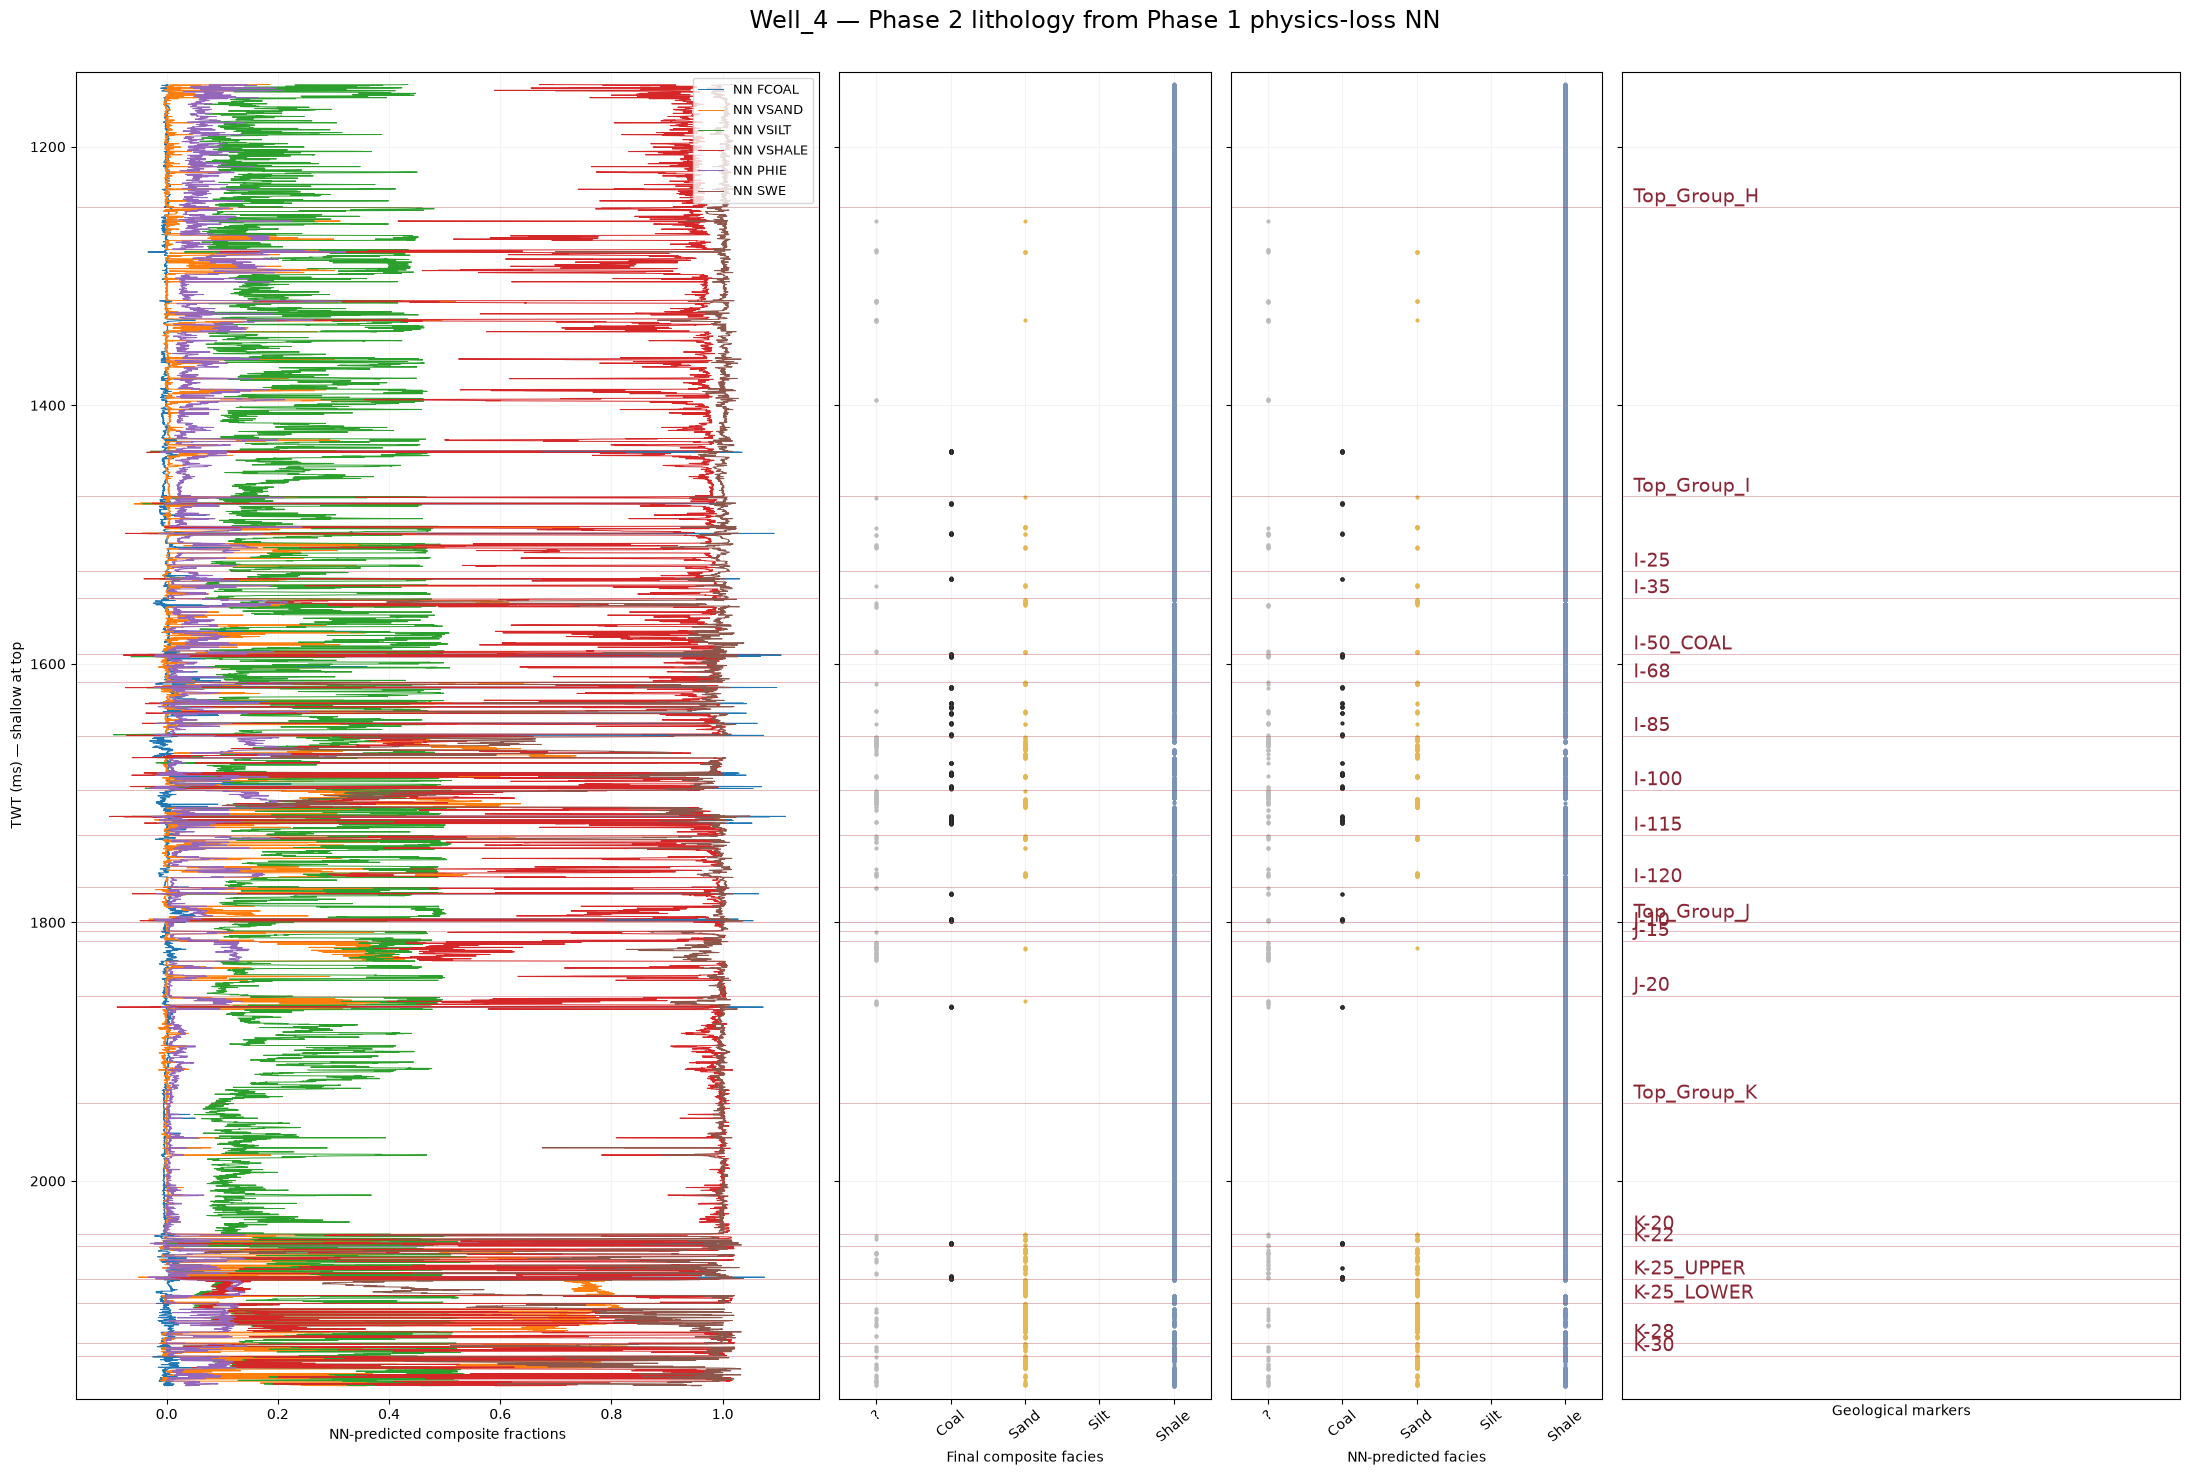

Well_6: markers parsed=15, valid TWT=15


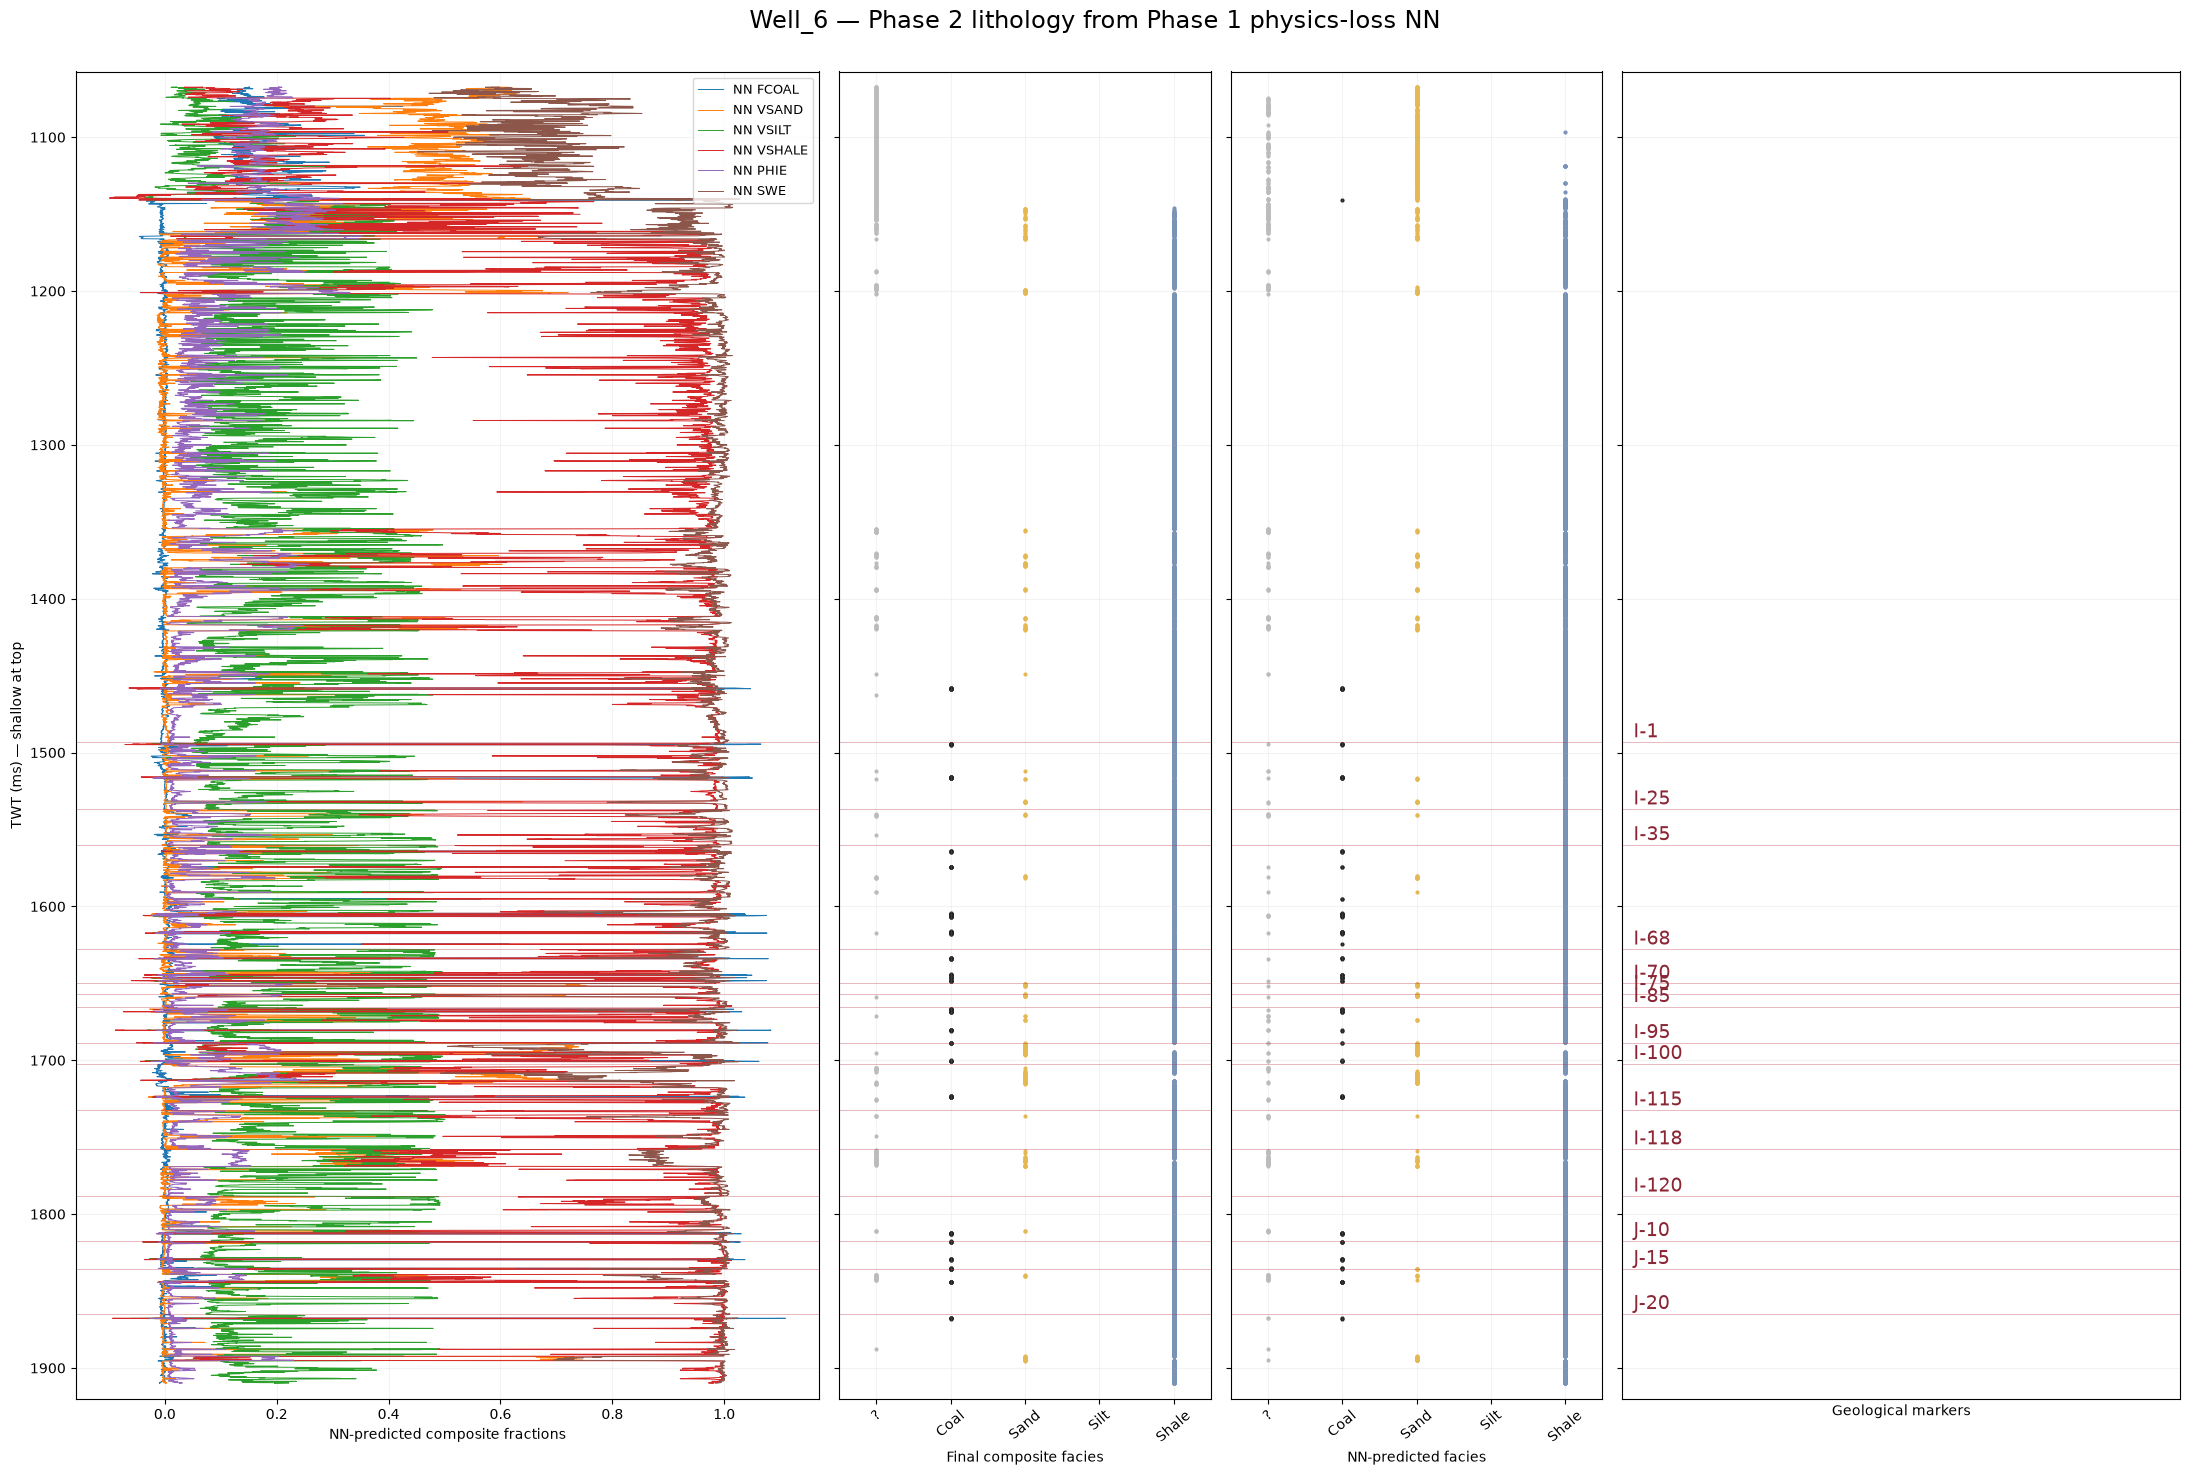

Well_7: markers parsed=7, valid TWT=7


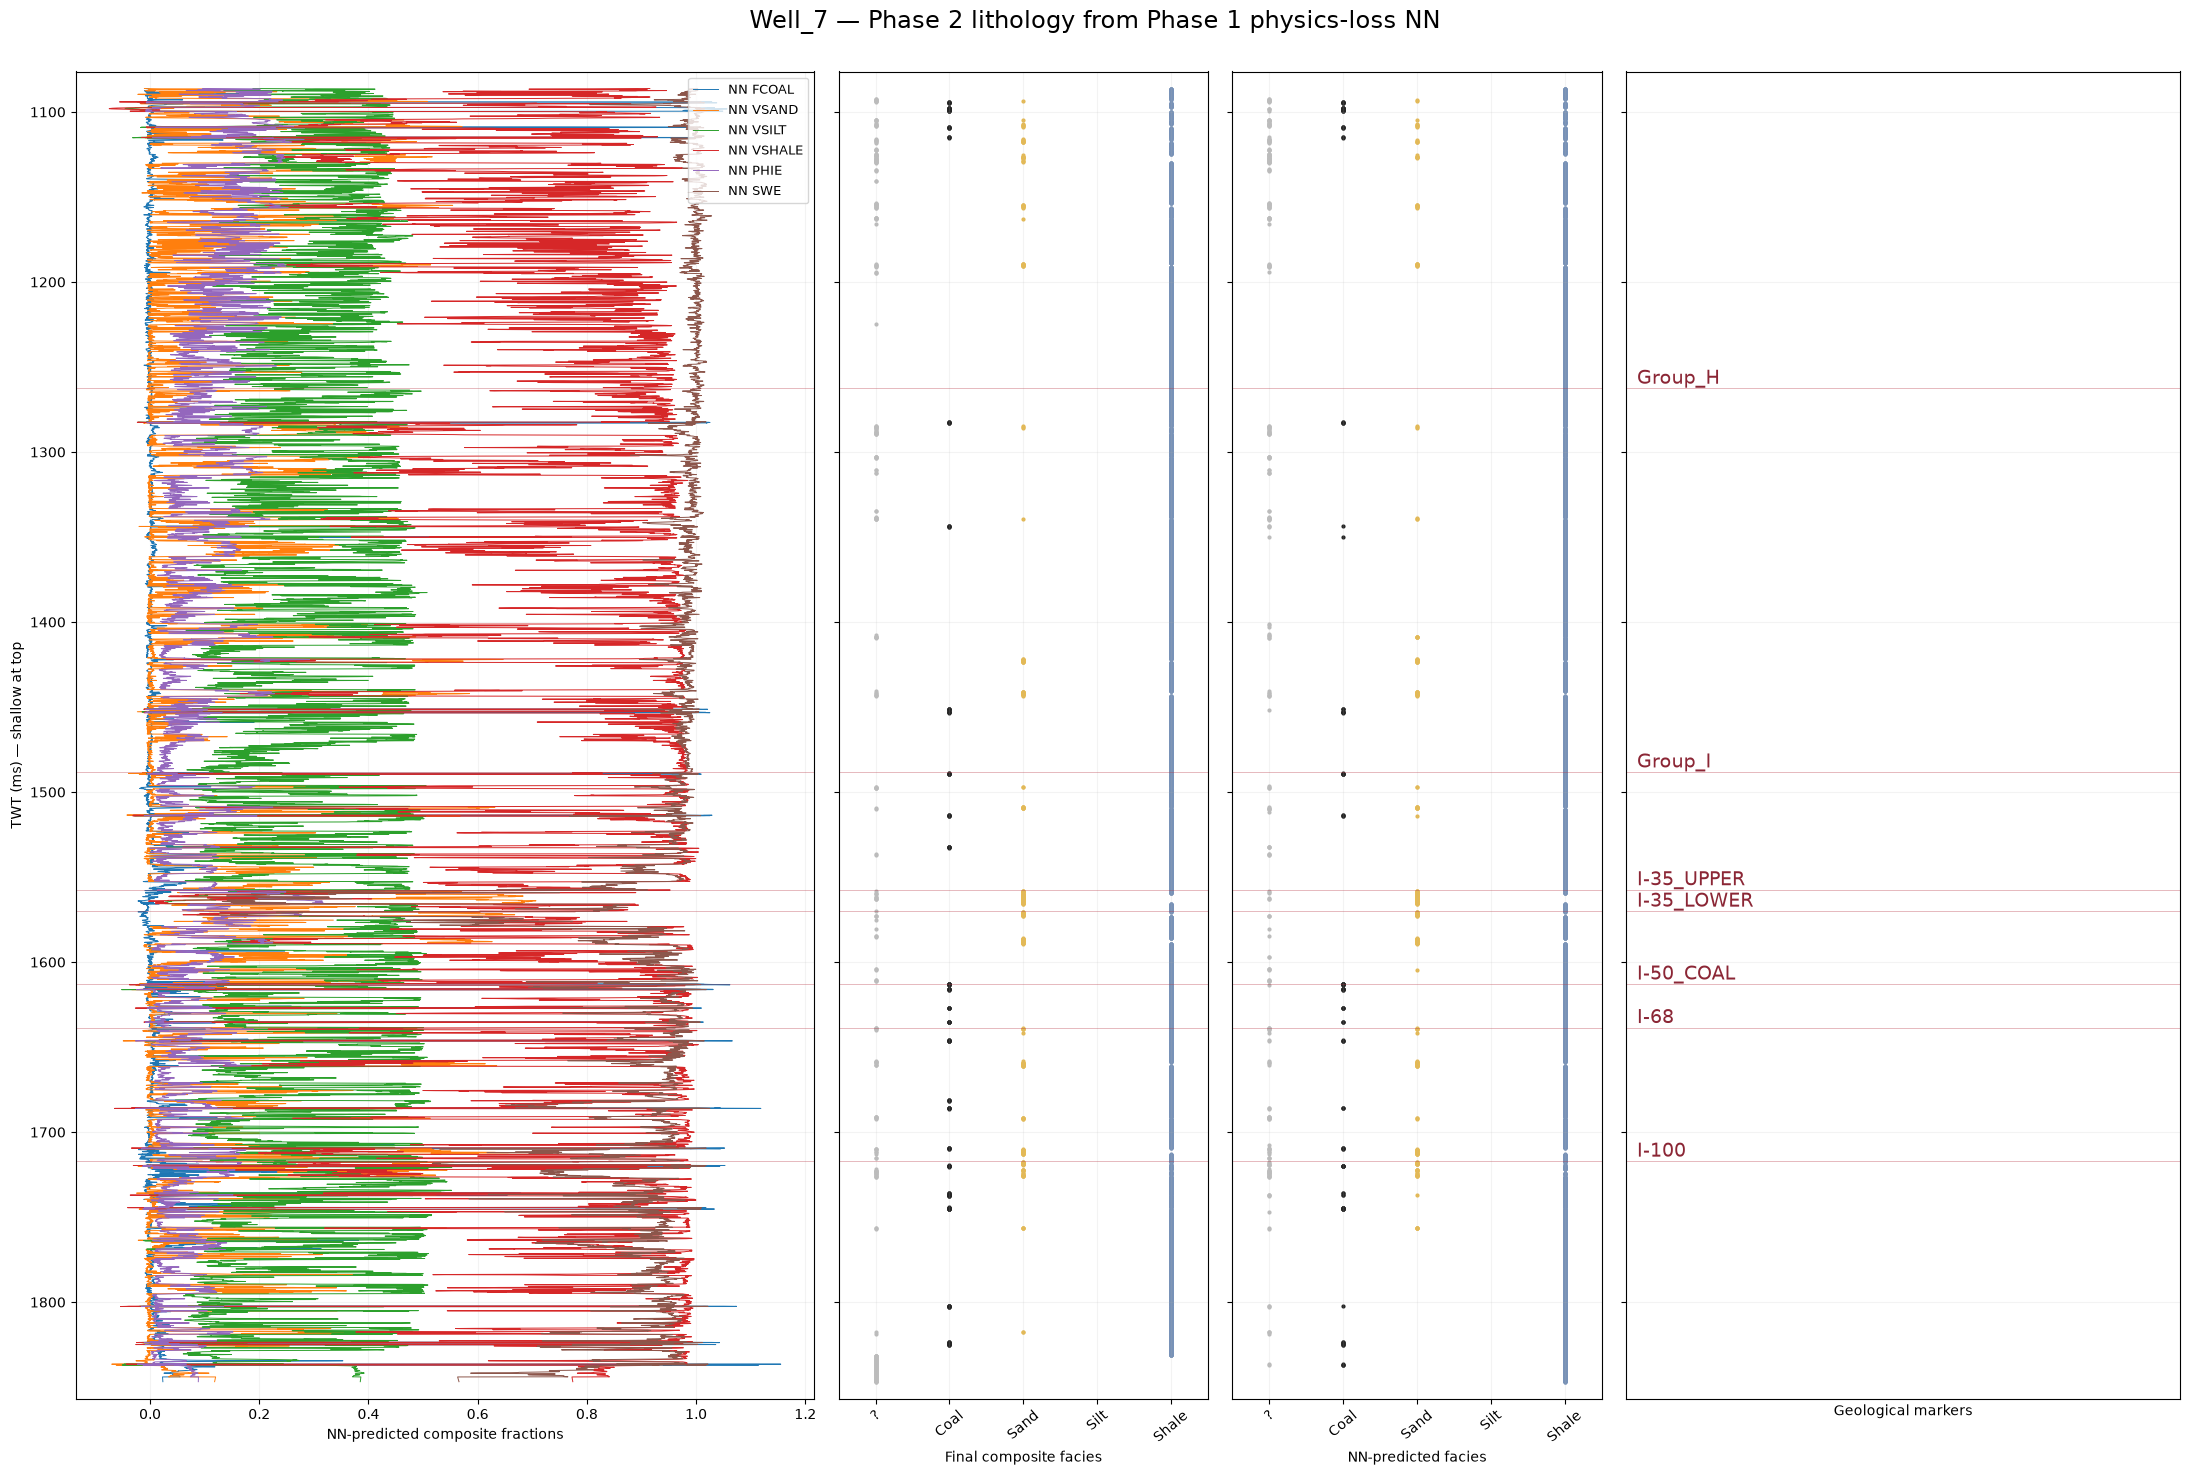

In [86]:
# Phase 2F — Three-row TWT QC: finalized lithology vs NN-derived lithology + markers
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.ticker import MaxNLocator

for well in WELLS:
    pred=FACIES_PRED[well].loc[FACIES_PRED[well].TWT_ms.notna()].sort_values('TWT_ms')
    final=FACIES_FINAL[well].loc[FACIES_FINAL[well].TWT_ms.notna()].sort_values('TWT_ms')
    markers=WELLS[well]['markers']
    good_markers=markers.loc[markers.TWT_ms.notna()].sort_values('TWT_ms')
    print(f'{well}: markers parsed={len(markers)}, valid TWT={len(good_markers)}')
    if len(markers) and good_markers.empty: warnings.warn(f'{well}: NO valid marker TWT; inspect checkshot / marker parser')
    if pred.empty:print(well,'No valid NN prediction TWT; skipping plot');continue
    fig,axes=plt.subplots(1,4,figsize=(22,15),sharey=True,gridspec_kw={'width_ratios':[2,1,1,1.5]})
    plot=pred.iloc[::max(1,int(np.ceil(len(pred)/PLOT_MAX_POINTS)))]
    for curve in ('FCOAL','VSAND','VSILT','VSHALE','PHIE','SWE'):
        if curve in plot and plot[curve].notna().any():
            axes[0].plot(plot[curve],plot.TWT_ms,lw=.7,label='NN '+curve)
    axes[0].legend(fontsize=9,loc='upper right');axes[0].set_xlabel('NN-predicted composite fractions')
    for ax,df,title in [(axes[1],final,'Final composite facies'),(axes[2],pred,'NN-predicted facies')]:
        sub=df.iloc[::max(1,int(np.ceil(len(df)/PLOT_MAX_POINTS)))]
        for code in range(5):
            mask=sub.LITHOLOGY_CODE.to_numpy()==code
            ax.scatter(np.full(mask.sum(),code),sub.TWT_ms.to_numpy()[mask],s=4,
                       c=LITHO_COLORS[code],rasterized=True)
        ax.set_xlim(-.5,4.5);ax.set_xticks(range(5),['?','Coal','Sand','Silt','Shale'],rotation=40)
        ax.set_xlabel(title)
    axes[3].set_xlim(0,1);axes[3].set_xticks([]);axes[3].set_xlabel('Geological markers')
    for _,m in good_markers.iterrows():
        t=float(m.TWT_ms)
        for ax in axes:ax.axhline(t,color='#B53542',lw=.6,alpha=.4)
        axes[3].text(.02,t,str(m.Marker),fontsize=14,color='#8B2635',va='bottom')
    ys=[pred.TWT_ms.min(),pred.TWT_ms.max()]
    if not final.empty:ys.extend([final.TWT_ms.min(),final.TWT_ms.max()])
    if not good_markers.empty:ys.extend([good_markers.TWT_ms.min(),good_markers.TWT_ms.max()])
    axes[0].set_ylim(max(ys)+10,min(ys)-10)
    axes[0].set_ylabel('TWT (ms) — shallow at top')
    for ax in axes:ax.grid(alpha=.15)
    fig.suptitle(f'{well} — Phase 2 lithology from Phase 1 physics-loss NN',fontsize=17)
    fig.tight_layout(rect=[0,0,1,.975]);fig.savefig(PHASE2_OUT/f'{well}_Phase2_NN_Lithology_TWT_QC.png',dpi=150)
    plt.show();plt.close(fig)


In [87]:
# Phase 2G — Save all results and manifest
for well in WELLS:
    PRED_COMPOSITES[well].to_csv(PHASE2_OUT/f'{well}_Phase1_NN_Predicted_Composite.csv',index=False)
    FACIES_PRED[well].to_csv(PHASE2_OUT/f'{well}_Phase2_NN_Lithology.csv',index=False)
    FACIES_FINAL[well].to_csv(PHASE2_OUT/f'{well}_Phase2_FinalComposite_Reference_Lithology.csv',index=False)
COAL_BEDS.to_csv(PHASE2_OUT/'Phase2_Coal_Beds_Predicted_vs_Final.csv',index=False)
FACIES_QC.to_csv(PHASE2_OUT/'Phase2_Facies_Distribution.csv',index=False)
FACIES_COMPARE.to_csv(PHASE2_OUT/'Phase2_Facies_Sample_Comparison.csv',index=False)
AGREEMENT.to_csv(PHASE2_OUT/'Phase2_Facies_Agreement.csv',index=False)
metadata={'source_model':str(PHASE1_MODEL_PATH),'source_manifest':str(PHASE1_MANIFEST_PATH),
          'wells':list(WELLS),'datum_offsets_m':DATUM_OVERRIDES_M,
          'coal_threshold':COAL_THRESHOLD,'dominant_min_fraction':DOMINANT_MIN_FRACTION,
          'dominance_margin':DOMINANCE_MARGIN,'min_coal_thickness_m':MIN_COAL_THICKNESS_M,
          'note':'Phase 2 labels are provisional; all 3 wells were used in final Phase 1 model training; agreement is in-sample.'}
(PHASE2_OUT/'Phase2_Manifest.json').write_text(json.dumps(metadata,indent=2))
print('Phase 2 outputs:',PHASE2_OUT)


Phase 2 outputs: /home/apgce_team_08/link-to-apgce_team_08/Well_4_6_7_Phase2_From_PhysicsLossNN_Output


# Phase 3 — Reservoir and fluid classes + transferable learning package

**Wells 4, 6, 7.** Run all preceding Phase 1 inference and Phase 2 cells first. Phase 3 assigns **0 non-reservoir, 1 water-bearing, 2 oil-bearing, 3 gas-bearing** and **-1 unknown/ambiguous**. It then trains a separate Phase 3 classifier using Phase 1 **predicted** composite curves as inputs and **finalized-composite-derived provisional flags** as training labels. This mirrors future-well inference without requiring finalized composite inputs. The classifier, interpretation rules, metadata and Phase 1 artifact references are exported for a subsequent Phase 4 deployment notebook.

**Limitations:** These are *provisional petrophysical interpretations*, not verified fluid contacts or independent ground truth. Gas/oil fractions and water saturation may use different physical definitions. The defaults must be calibrated to test, core, fluid-contact and petrophysical evidence. Phase 1 final network was trained on all three wells: Phase 3 LOWO classification is **not an independent end-to-end validation**.
**Thickness qualification:** Water/oil/gas classes (1/2/3) must form a contiguous reservoir interval of at least **1.5 m measured-depth thickness**, editable in Phase 3A. Adjacent fluid classes count toward the same reservoir interval; non-reservoir/unknown and depth gaps break it. Thin intervals are reclassified as non-reservoir (0). Single isolated samples cannot establish 1.5 m. This is measured-depth thickness, not true stratigraphic thickness.


In [88]:
# Phase 3A — EDITABLE fluid/reservoir interpretation thresholds
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score, f1_score
import shutil

PHASE3_OUT = BASE / 'Well_4_6_7_Phase3_FluidReservoir_Output'
PHASE3_OUT.mkdir(parents=True, exist_ok=True)

PHASE3_PARAMS = {

    'min_reservoir_thickness_m': 0,  # EDIT HERE: minimum contiguous reservoir thickness (MD metres) for classes 1, 2, 3
    'max_reservoir_sample_gap_m': 0.5, # EDIT HERE: larger MD gaps split a reservoir interval
    'min_phie': 0.06,                 # minimum effective porosity to consider reservoir
    'max_shale_fraction': 0.55,      # shale/clay exclusion threshold
    'max_coal_fraction': 0.30,       # coal exclusion threshold
    'min_sand_fraction': 0.35,       # optional reservoir lithology evidence
    'require_sand_evidence': False,  # False allows uncertain lithology if porosity + shale tests pass
    'water_swe_min': 0.60,           # water-bearing if water saturation >= this
    'hydrocarbon_swe_max': 0.60,     # HC candidate if SWE <= this
    'gas_fraction_min': 0.20,        # provisional gas/oil composite indicator, not saturation
    'oil_fraction_min': 0.20,
    'fluid_dominance_margin': 0.08,  # difference between VGAS and VOIL to resolve fluid
    'use_lithology_gate': True,
}
# Leave unclassified (-1) where porosity, fluid or reservoir evidence is missing/ambiguous.
PHASE3_MODEL_FEATURES = ['PHIE','PHIT','SWE','VGAS','VOIL','VSAND','VSILT',
                         'FCOAL','VSHALE','VCLW','VCLB','VCLD','VSHGR',
                         'PERMH','DENB','DTCOM','DTSH']
PHASE3_MIN_TRAIN_SAMPLES = 100
PHASE3_MIN_TEST_SAMPLES = 20
PHASE3_MIN_CLASS_SAMPLES = 15
PHASE3_TREES = 400
PHASE3_MIN_LEAF = 5
PHASE3_MAX_ROWS_PER_WELL = 30000
PHASE3_CONFIDENCE_THRESHOLD = 0.55  # below -> unknown (-1) at prediction time
FLUID_NAMES = {-1:'Unknown / ambiguous',0:'Non-reservoir',1:'Water-bearing',
               2:'Oil-bearing',3:'Gas-bearing'}
FLUID_COLORS = {-1:'#BDBDBD',0:'#555555',1:'#4B91D1',2:'#57A66A',3:'#DD8D3F'}
print('Phase 3 output:',PHASE3_OUT)
print('Review all provisional thresholds in PHASE3_PARAMS before interpretation.')
print('Minimum reservoir thickness (m):', PHASE3_PARAMS['min_reservoir_thickness_m'])
print('Maximum contiguous sample gap (m):', PHASE3_PARAMS['max_reservoir_sample_gap_m'])


Phase 3 output: /home/apgce_team_08/link-to-apgce_team_08/Well_4_6_7_Phase3_FluidReservoir_Output
Review all provisional thresholds in PHASE3_PARAMS before interpretation.
Minimum reservoir thickness (m): 0
Maximum contiguous sample gap (m): 0.5


In [89]:
# Phase 3B — Deterministic reference and predicted-composite fluid flags
# Do not conflate hydrocarbon volume fractions (VGAS, VOIL) with fluid saturations.
# Missing / contradictory evidence remains UNKNOWN rather than forced into class 0.
def numeric_curve(df, name):
    if name not in df.columns: return np.full(len(df), np.nan, dtype=float)
    return pd.to_numeric(df[name], errors='coerce').to_numpy(dtype=float, copy=True)

def first_available_curve(df, candidates):
    for c in candidates:
        if c in df and pd.to_numeric(df[c],errors='coerce').notna().any():
            return c
    return None

# Apply the minimum-thickness criterion to CONTIGUOUS reservoir intervals,
# regardless of whether adjacent samples are water-, oil-, or gas-bearing.
# Intervals are evaluated independently for each well and split at nonreservoir,
# unknown samples, or a measured-depth gap above the editable threshold.
# MD thickness is an along-wellbore thickness, NOT true stratigraphic thickness.
def enforce_reservoir_thickness(df, flag_col, params=PHASE3_PARAMS, reason_col=None):
    out=df.copy()
    if 'MDKB_m' not in out.columns:
        raise KeyError('MDKB_m required to calculate reservoir thickness')
    min_thick=float(params['min_reservoir_thickness_m'])
    max_gap=float(params['max_reservoir_sample_gap_m'])
    if min_thick < 0 or max_gap <= 0:
        raise ValueError('Minimum thickness must be >=0 and maximum sample gap must be >0')
    if 'Well' in out.columns:
        groups=out.groupby('Well',sort=False,dropna=False)
    else:
        groups=[('single_well',out)]
    out['RESERVOIR_INTERVAL_ID']=pd.Series(pd.NA,index=out.index,dtype='Int64')
    out['RESERVOIR_INTERVAL_THICKNESS_M']=np.nan
    out['THIN_RESERVOIR_REMOVED']=False
    for _,part in groups:
        part=part.sort_values('MDKB_m',kind='stable')
        md=pd.to_numeric(part.MDKB_m,errors='coerce').to_numpy(dtype=float,copy=True)
        flags=pd.to_numeric(part[flag_col],errors='coerce').to_numpy(dtype=float,copy=True)
        eligible=np.isin(flags,[1,2,3]) & np.isfinite(md)
        starts=eligible & np.r_[True, (~eligible[:-1]) | (~np.isfinite(md[:-1])) |
                                ((md[1:]-md[:-1]) > max_gap) | ((md[1:]-md[:-1]) <= 0)]
        segment=np.cumsum(starts)
        interval_no=0
        for sid in np.unique(segment[eligible]):
            ix=np.flatnonzero(eligible & (segment==sid))
            if not len(ix):continue
            interval_no+=1
            # Thickness from sample-centre depths; endpoints extended by half
            # of the adjacent sample spacing, capped at max_gap. A single
            # isolated sample has unverified thickness and cannot qualify.
            if len(ix)<2:
                thickness=0.0
            else:
                local=md[ix]
                d=np.diff(local)
                thickness=float(local[-1]-local[0]+0.5*min(d[0],max_gap)+0.5*min(d[-1],max_gap))
            idx=part.index[ix]
            out.loc[idx,'RESERVOIR_INTERVAL_ID']=interval_no
            out.loc[idx,'RESERVOIR_INTERVAL_THICKNESS_M']=thickness
            if thickness+1e-9 < min_thick:
                out.loc[idx,flag_col]=0
                out.loc[idx,'THIN_RESERVOIR_REMOVED']=True
                if reason_col is not None:
                    out.loc[idx,reason_col]='RESERVOIR_INTERVAL_BELOW_MIN_THICKNESS'
    return out

def fluid_flags(df, params=PHASE3_PARAMS):
    r=df.copy()
    phie=numeric_curve(r,'PHIE'); swe=numeric_curve(r,'SWE')
    gas=numeric_curve(r,'VGAS'); oil=numeric_curve(r,'VOIL')
    coal=numeric_curve(r,'FCOAL'); sand=numeric_curve(r,'VSAND')
    shale_name=first_available_curve(r,('VSHALE','VCLW','VCLB','VCLD','VSHGR'))
    shale=numeric_curve(r,shale_name) if shale_name else np.full(len(r),np.nan)
    n=len(r); flags=np.full(n,-1,dtype=np.int8)
    reasons=np.full(n,'INSUFFICIENT_EVIDENCE',dtype=object)
    valid_phie=np.isfinite(phie)&(phie>=0)&(phie<=1)
    nonres=valid_phie&(phie<params['min_phie'])
    if params['use_lithology_gate']:
        nonres |= np.isfinite(coal)&(coal>=params['max_coal_fraction'])
        nonres |= np.isfinite(shale)&(shale>=params['max_shale_fraction'])
    flags[nonres]=0; reasons[nonres]='LOW_POROSITY_OR_EXCLUDED_LITHOLOGY'
    eligible=valid_phie&(phie>=params['min_phie'])&(~nonres)
    if params['use_lithology_gate']:
        eligible &= (~np.isfinite(coal))|(coal<params['max_coal_fraction'])
        eligible &= (~np.isfinite(shale))|(shale<params['max_shale_fraction'])
        if params['require_sand_evidence']:
            eligible &= np.isfinite(sand)&(sand>=params['min_sand_fraction'])
    valid_swe=np.isfinite(swe)&(swe>=0)&(swe<=1)
    water=eligible&valid_swe&(swe>=params['water_swe_min'])
    flags[water]=1; reasons[water]='HIGH_WATER_SATURATION'
    hc=eligible&valid_swe&(swe<=params['hydrocarbon_swe_max'])
    gas_ok=np.isfinite(gas)&(gas>=params['gas_fraction_min'])
    oil_ok=np.isfinite(oil)&(oil>=params['oil_fraction_min'])
    gas_dominant=hc&gas_ok&((~oil_ok)|(gas-oil>=params['fluid_dominance_margin']))
    oil_dominant=hc&oil_ok&((~gas_ok)|(oil-gas>=params['fluid_dominance_margin']))
    flags[gas_dominant]=3; reasons[gas_dominant]='GAS_DOMINANT_HC_INDICATOR'
    flags[oil_dominant]=2; reasons[oil_dominant]='OIL_DOMINANT_HC_INDICATOR'
    # Unresolved 0.60 < SWE < 0.70, missing HC fractions, and close gas/oil scores remain unknown.
    r['FLUID_FLAG']=flags
    r['FLUID_CLASS']=[FLUID_NAMES[int(v)] for v in flags]
    r['FLUID_REASON']=reasons
    r['SHALE_GATE_CURVE']=shale_name or ''
    r=enforce_reservoir_thickness(r,'FLUID_FLAG',params,reason_col='FLUID_REASON')
    r['FLUID_CLASS']=[FLUID_NAMES[int(v)] for v in r['FLUID_FLAG']]
    return r

PHASE3_PRED={}; PHASE3_FINAL={}; PHASE3_DISTRIBUTION=[]
for well in WELLS:
    PHASE3_PRED[well]=fluid_flags(PRED_COMPOSITES[well])
    PHASE3_FINAL[well]=fluid_flags(WELLS[well]['comp'])
    for source,frame in [('Phase1_NN',PHASE3_PRED[well]),('Final_composite',PHASE3_FINAL[well])]:
        for code_,label in FLUID_NAMES.items():
            PHASE3_DISTRIBUTION.append({'Well':well,'Source':source,'Flag':code_,
                'Class':label,'N':int((frame.FLUID_FLAG==code_).sum()),
                'Pct':round(100*float((frame.FLUID_FLAG==code_).mean()),2)})
PHASE3_DISTRIBUTION=pd.DataFrame(PHASE3_DISTRIBUTION)
display(PHASE3_DISTRIBUTION)

,Well,Source,Flag,Class,N,Pct
0,Well_4,Phase1_NN,-1,Unknown / ambiguous,529,5.10
1,Well_4,Phase1_NN,0,Non-reservoir,9021,87.04
2,Well_4,Phase1_NN,1,Water-bearing,803,7.75
3,Well_4,Phase1_NN,2,Oil-bearing,8,0.08
4,Well_4,Phase1_NN,3,Gas-bearing,3,0.03
5,Well_4,Final_composite,-1,Unknown / ambiguous,800,7.72
6,Well_4,Final_composite,0,Non-reservoir,8676,83.71
7,Well_4,Final_composite,1,Water-bearing,880,8.49
8,Well_4,Final_composite,2,Oil-bearing,0,0.00
9,Well_4,Final_composite,3,Gas-bearing,8,0.08


In [90]:
# Phase 3C — Build training set: predicted composites -> finalized-derived flags
# Training on predicted composites matches future-well inference. Reference flags
# are joined by MD with tolerance; finalized composite curves NEVER enter features.
TRAIN3=[]
for well in WELLS:
    pred=PHASE3_PRED[well].sort_values('MDKB_m').copy()
    ref=PHASE3_FINAL[well][['MDKB_m','FLUID_FLAG']].sort_values('MDKB_m').copy()
    ref=ref.rename(columns={'FLUID_FLAG':'REFERENCE_FLAG'})
    matched=pd.merge_asof(pred,ref,on='MDKB_m',direction='nearest',tolerance=DEPTH_TOLERANCE_M)
    matched['Well']=well
    for feature in PHASE3_MODEL_FEATURES:
        if feature not in matched:matched[feature]=np.nan
    TRAIN3.append(matched)
PHASE3_DATA=pd.concat(TRAIN3,ignore_index=True)
PHASE3_DATA['REFERENCE_FLAG']=pd.to_numeric(PHASE3_DATA['REFERENCE_FLAG'],errors='coerce')
PHASE3_LABELLED=PHASE3_DATA.loc[PHASE3_DATA.REFERENCE_FLAG.isin([0,1,2,3])].copy()
print('Reference label counts by well (unknown labels excluded from supervised training):')
display(pd.crosstab(PHASE3_LABELLED.Well,PHASE3_LABELLED.REFERENCE_FLAG))
print('Labeled samples:',len(PHASE3_LABELLED),'/',len(PHASE3_DATA))
print('WARNING: Final Phase 1 NN was fitted on these wells; LOWO below is diagnostic, not independent end-to-end generalization.')

Reference label counts by well (unknown labels excluded from supervised training):


REFERENCE_FLAG,0,1,2,3
Well,,,,
Well_4,8676,880,0,8
Well_6,6416,0,0,0
Well_7,6210,777,48,0


Labeled samples: 23015 / 25585


In [91]:
# Phase 3D — Leave-one-well-out classifier diagnostics
# Classifier is trained on Phase 1 predicted curves, evaluated on held-out
# well reference-derived labels. No test-well labels enter classifier fitting.
from sklearn.metrics import recall_score

def make_phase3_classifier():
    return Pipeline([
        ('imputer',SimpleImputer(strategy='median',keep_empty_features=True)),
        ('model',ExtraTreesClassifier(n_estimators=PHASE3_TREES,
                    min_samples_leaf=PHASE3_MIN_LEAF,class_weight='balanced',
                    n_jobs=N_JOBS,random_state=RANDOM_STATE))])

def depth_cap(df,cap):
    if not cap or len(df)<=cap:return df.copy()
    return df.iloc[np.unique(np.linspace(0,len(df)-1,cap,dtype=int))].copy()

LOWO3_METRICS=[]; LOWO3_PRED=[]
for heldout in WELLS:
    train_parts=[]
    for w in WELLS:
        if w!=heldout:
            part=PHASE3_LABELLED.loc[PHASE3_LABELLED.Well==w].sort_values('MDKB_m')
            train_parts.append(depth_cap(part,PHASE3_MAX_ROWS_PER_WELL))
    tr=pd.concat(train_parts,ignore_index=True)
    te=PHASE3_LABELLED.loc[PHASE3_LABELLED.Well==heldout].sort_values('MDKB_m').copy()
    # Keep full held-out depth sampling: thinning rows would falsely break beds.
    # te is intentionally NOT depth-capped before thickness qualification.
    if len(tr)<PHASE3_MIN_TRAIN_SAMPLES or len(te)<PHASE3_MIN_TEST_SAMPLES or tr.REFERENCE_FLAG.nunique()<2:
        print(f'{heldout}: skipped (train={len(tr)}, test={len(te)}, classes={tr.REFERENCE_FLAG.nunique()})')
        continue
    model3=make_phase3_classifier()
    model3.fit(tr[PHASE3_MODEL_FEATURES],tr.REFERENCE_FLAG.astype(int))
    probs=model3.predict_proba(te[PHASE3_MODEL_FEATURES])
    best_ix=np.argmax(probs,axis=1); conf=probs[np.arange(len(te)),best_ix]
    pred=np.asarray(model3.classes_,dtype=int)[best_ix]
    pred=np.where(conf>=PHASE3_CONFIDENCE_THRESHOLD,pred,-1)
    # Apply thickness rule to predictions before validation metrics.
    qc_thickness=te[['MDKB_m']].copy()
    qc_thickness['ML_FLUID_FLAG']=pred
    qc_thickness=enforce_reservoir_thickness(qc_thickness,'ML_FLUID_FLAG')
    pred=qc_thickness['ML_FLUID_FLAG'].to_numpy(dtype=int,copy=True)
    truth=te.REFERENCE_FLAG.to_numpy(dtype=int,copy=True)
    coverage=float(np.mean(pred!=-1))
    covered=pred!=-1
    # Calculate balanced accuracy without single-class warnings
if covered.any():
    y_true_covered = truth[covered]
    y_pred_covered = pred[covered]

    # Evaluate recall for classes actually present in reference labels
    present_classes = np.unique(y_true_covered)

    class_recalls = recall_score(
        y_true_covered,
        y_pred_covered,
        labels=present_classes,
        average=None,
        zero_division=0
    )

    balanced_acc = float(np.mean(class_recalls))
else:
    balanced_acc = np.nan
    LOWO3_METRICS.append({'Heldout_Well':heldout,'Train_N':len(tr),'Test_N':len(te),
        'Train_Classes':','.join(map(str,sorted(model3.classes_))),
        'Coverage':coverage,
        'Accuracy_Covered':float(np.mean(pred[covered]==truth[covered])) if covered.any() else np.nan,
        'Balanced_Accuracy_Covered': balanced_acc,
        'Macro_F1_Covered':float(f1_score(truth[covered],pred[covered],average='macro',zero_division=0)) if covered.any() else np.nan})
    qc=te[['Well','MDKB_m','TWT_ms']].copy()
    qc['Reference_Flag']=truth;qc['ML_Flag']=pred;qc['Confidence']=conf
    LOWO3_PRED.append(qc)
    print(f'{heldout}: coverage={coverage:.1%}; classes={list(model3.classes_)}')
LOWO3_TABLE=pd.DataFrame(LOWO3_METRICS)
LOWO3_SAMPLES=pd.concat(LOWO3_PRED,ignore_index=True) if LOWO3_PRED else pd.DataFrame()
display(LOWO3_TABLE.round(3))

""


In [92]:
# Phase 3E — Final Phase 3 classifier trained on all three wells
# A model cannot learn a class absent from the reference data; inspect counts.
if len(PHASE3_LABELLED)<PHASE3_MIN_TRAIN_SAMPLES or PHASE3_LABELLED.REFERENCE_FLAG.nunique()<2:
    raise RuntimeError('Insufficient labeled samples or fewer than two fluid classes. Review Phase 3A thresholds and source curves.')
train_all=pd.concat([depth_cap(PHASE3_LABELLED.loc[PHASE3_LABELLED.Well==w].sort_values('MDKB_m'),
                         PHASE3_MAX_ROWS_PER_WELL) for w in WELLS],ignore_index=True)
FINAL_PHASE3_MODEL=make_phase3_classifier()
FINAL_PHASE3_MODEL.fit(train_all[PHASE3_MODEL_FEATURES],train_all.REFERENCE_FLAG.astype(int))
print('Final classifier trained:',len(train_all),'samples; classes:',list(FINAL_PHASE3_MODEL.classes_))
missing_classes=set([0,1,2,3])-set(FINAL_PHASE3_MODEL.classes_)
if missing_classes: warnings.warn(f'Fluid classes {sorted(missing_classes)} have no training examples and cannot be predicted.')

def phase3_predict(frame,model=FINAL_PHASE3_MODEL):
    data=frame.reindex(columns=PHASE3_MODEL_FEATURES)
    proba=model.predict_proba(data)
    j=np.argmax(proba,axis=1); confidence=proba[np.arange(len(frame)),j]
    flags=np.asarray(model.classes_,dtype=int)[j]
    flags=np.where(confidence>=PHASE3_CONFIDENCE_THRESHOLD,flags,-1)
    valid=data.notna().any(axis=1).to_numpy()
    flags=np.where(valid,flags,-1)
    result=pd.DataFrame({'ML_FLUID_FLAG':flags,'ML_FLUID_CLASS':[FLUID_NAMES[int(v)] for v in flags],
                         'ML_CONFIDENCE':np.where(valid,confidence,np.nan)},index=frame.index)
    # Apply reservoir-thickness rule to the final classifier output too.
    # Keep all original input rows and their MD; do not use TWT for thickness.
    result['MDKB_m']=frame['MDKB_m'].to_numpy(copy=True)
    if 'Well' in frame.columns:
        result['Well']=frame['Well'].to_numpy(copy=True)
    result=enforce_reservoir_thickness(result,'ML_FLUID_FLAG')
    result['ML_FLUID_CLASS']=[FLUID_NAMES[int(v)] for v in result.ML_FLUID_FLAG]
    result=result.drop(columns=['MDKB_m','Well'],errors='ignore')
    for c,cls in enumerate(model.classes_):result[f'P_CLASS_{int(cls)}']=proba[:,c]
    return result

PHASE3_ML={}
for well in WELLS:
    base=PHASE3_PRED[well].copy()
    pred=phase3_predict(base)
    PHASE3_ML[well]=pd.concat([base.reset_index(drop=True),pred.reset_index(drop=True)],axis=1)
    print(well,'ML flags:',PHASE3_ML[well].ML_FLUID_CLASS.value_counts().to_dict())

Final classifier trained: 23015 samples; classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Well_4 ML flags: {'Non-reservoir': 8934, 'Water-bearing': 1223, 'Unknown / ambiguous': 150, 'Oil-bearing': 45, 'Gas-bearing': 12}
Well_6 ML flags: {'Non-reservoir': 6405, 'Water-bearing': 1259, 'Unknown / ambiguous': 138}
Well_7 ML flags: {'Non-reservoir': 6300, 'Water-bearing': 958, 'Unknown / ambiguous': 87, 'Oil-bearing': 74}


In [93]:
# Phase 3E-1 — Fill unknown (-1) fluid flags by nearest valid depth neighbour
# Runs after Phase 3E and BEFORE Phase 3F / Phase 3G.
# Only fills unknown classifications. Existing classes 0/1/2/3 are unchanged.
# Uses MDKB (metres), not row index or TWT, for nearest-neighbour distance.
# A direct nearest-valid assignment is equivalent to repeatedly propagating
# neighbour labels until no -1 remains, but avoids slow iterative loops.
import numpy as np
import pandas as pd

FILL_UNKNOWN_CLASS = -1
VALID_FLUID_CLASSES = (0, 1, 2, 3)
FILL_UNKNOWN_ALL_TRACKS = True  # True: reference + NN-rule + ML; False: ML only

def fill_unknown_nearest_depth(frame, flag_col, depth_col='MDKB_m'):
    out = frame.copy()
    flags = pd.to_numeric(out[flag_col], errors='coerce').fillna(-1).to_numpy(dtype=np.int32, copy=True)
    depth = pd.to_numeric(out[depth_col], errors='coerce').to_numpy(dtype=float, copy=True)

    if not np.isfinite(depth).all():
        raise ValueError(f'{flag_col}: non-finite MDKB values; cannot perform depth-based nearest-neighbour fill')
    if not np.isin(flags, [FILL_UNKNOWN_CLASS, *VALID_FLUID_CLASSES]).all():
        raise ValueError(f'{flag_col}: unexpected class codes present')

    known = np.flatnonzero(np.isin(flags, VALID_FLUID_CLASSES))
    missing = np.flatnonzero(flags == FILL_UNKNOWN_CLASS)
    if not len(missing):
        return out, 0
    if not len(known):
        raise ValueError(f'{flag_col}: all {len(flags)} samples are -1; no valid neighbour exists to fill from')

    # Sort by MDKB to support unsorted input rows and repeated depths.
    order = np.argsort(depth, kind='stable')
    sorted_depth = depth[order]
    sorted_flags = flags[order]
    known_sorted = np.flatnonzero(np.isin(sorted_flags, VALID_FLUID_CLASSES))
    missing_sorted = np.flatnonzero(sorted_flags == FILL_UNKNOWN_CLASS)
    insert = np.searchsorted(known_sorted, missing_sorted, side='left')
    left = known_sorted[np.maximum(insert - 1, 0)]
    right = known_sorted[np.minimum(insert, len(known_sorted) - 1)]
    # On exact distance ties, choose shallower/earlier valid sample.
    use_right = np.abs(sorted_depth[right] - sorted_depth[missing_sorted]) < np.abs(
        sorted_depth[missing_sorted] - sorted_depth[left])
    nearest = np.where(use_right, right, left)
    sorted_flags[missing_sorted] = sorted_flags[nearest]
    flags[order] = sorted_flags

    assert not np.any(flags == FILL_UNKNOWN_CLASS)
    out[flag_col] = flags
    return out, len(missing)

targets = (
    [('Final reference', PHASE3_FINAL, 'FLUID_FLAG'),
     ('NN rule', PHASE3_PRED, 'FLUID_FLAG'),
     ('ML prediction', PHASE3_ML, 'ML_FLUID_FLAG')]
    if FILL_UNKNOWN_ALL_TRACKS else
    [('ML prediction', PHASE3_ML, 'ML_FLUID_FLAG')]
)
for label, collection, col in targets:
    for well in WELLS:
        updated, n_filled = fill_unknown_nearest_depth(collection[well], col)
        class_col = 'ML_FLUID_CLASS' if col == 'ML_FLUID_FLAG' else 'FLUID_CLASS'
        if class_col in updated.columns:
            updated[class_col] = [FLUID_NAMES[int(v)] for v in updated[col]]
        collection[well] = updated
        print(f'{well} | {label}: filled {n_filled:,} unknown samples; remaining -1 = {(updated[col] == -1).sum():,}')
print('Nearest-neighbour completion finished. Original known classifications were preserved.')


Well_4 | Final reference: filled 800 unknown samples; remaining -1 = 0
Well_6 | Final reference: filled 1,386 unknown samples; remaining -1 = 0
Well_7 | Final reference: filled 384 unknown samples; remaining -1 = 0
Well_4 | NN rule: filled 529 unknown samples; remaining -1 = 0
Well_6 | NN rule: filled 160 unknown samples; remaining -1 = 0
Well_7 | NN rule: filled 169 unknown samples; remaining -1 = 0
Well_4 | ML prediction: filled 150 unknown samples; remaining -1 = 0
Well_6 | ML prediction: filled 138 unknown samples; remaining -1 = 0
Well_7 | ML prediction: filled 87 unknown samples; remaining -1 = 0
Nearest-neighbour completion finished. Original known classifications were preserved.


Saved full-depth QC: /home/apgce_team_08/link-to-apgce_team_08/Well_4_6_7_Phase3_FluidReservoir_Output/Well_4_Phase3_3Row_TWT_QC.png


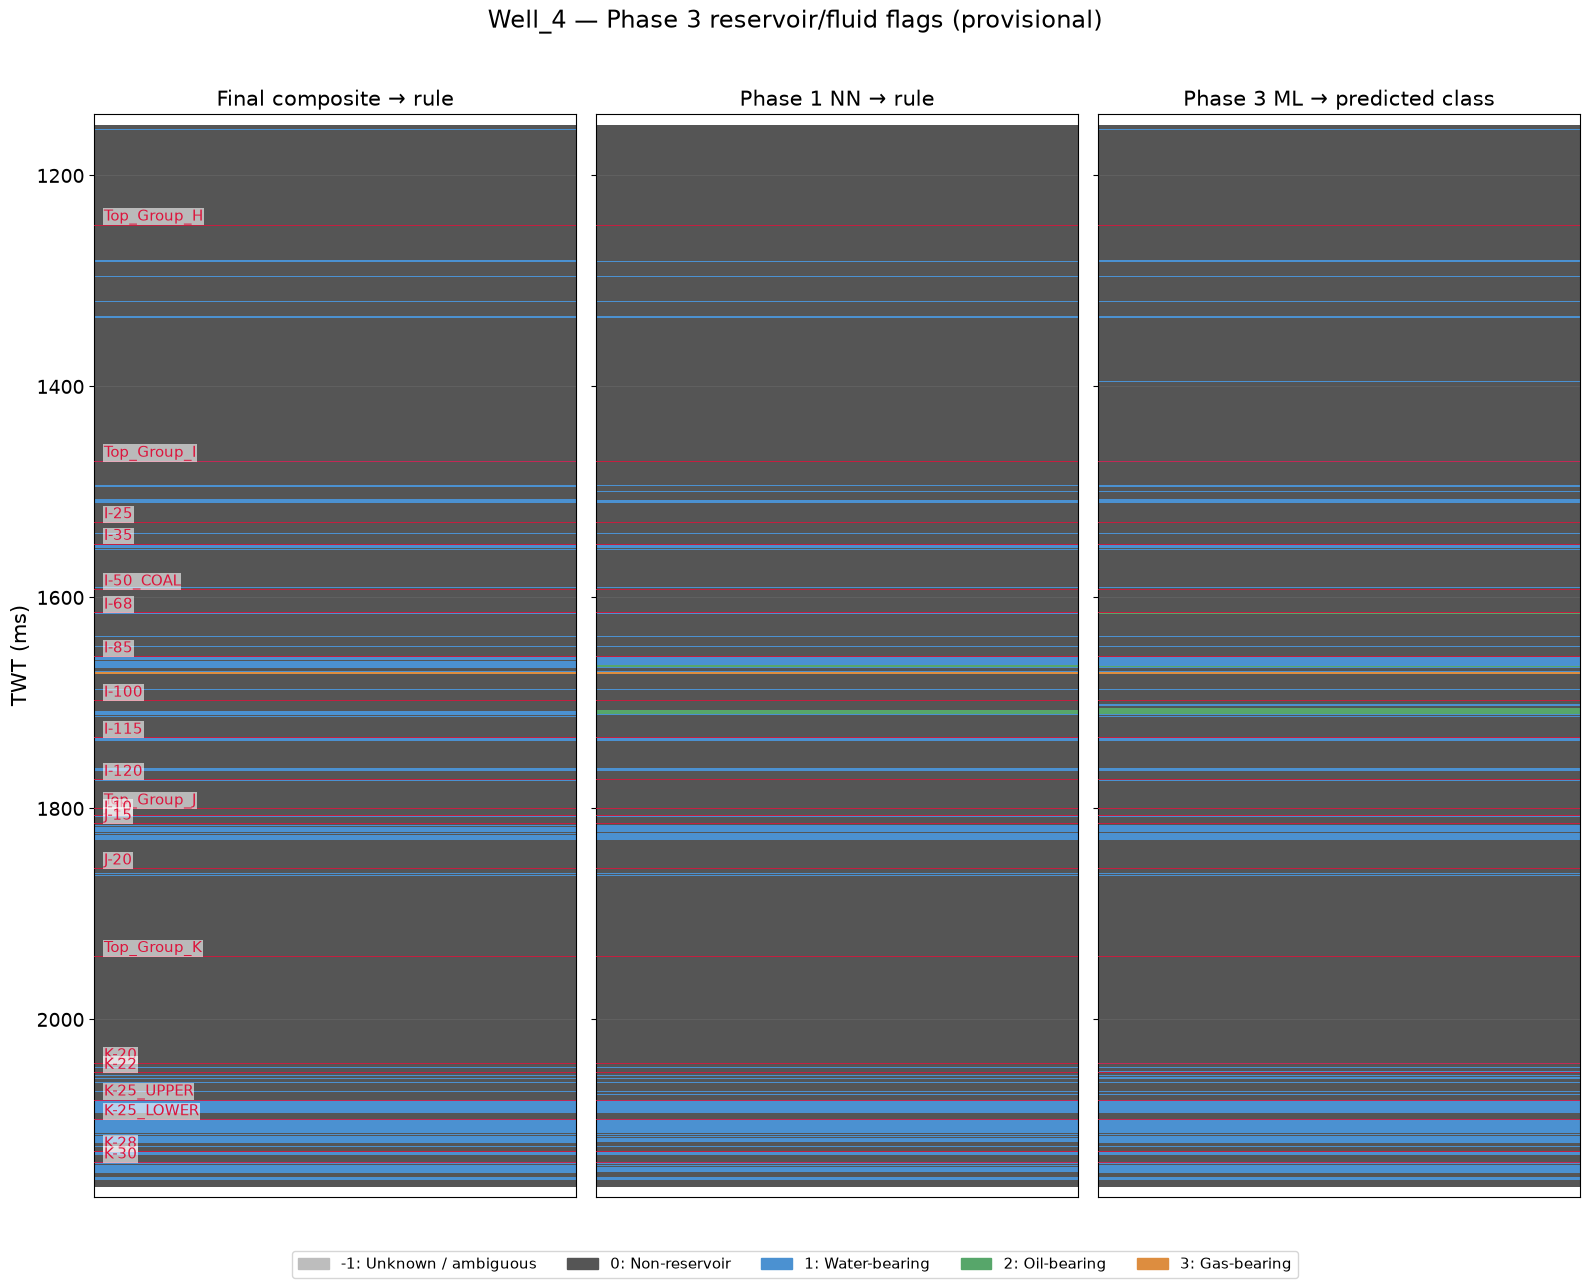

Saved full-depth QC: /home/apgce_team_08/link-to-apgce_team_08/Well_4_6_7_Phase3_FluidReservoir_Output/Well_6_Phase3_3Row_TWT_QC.png


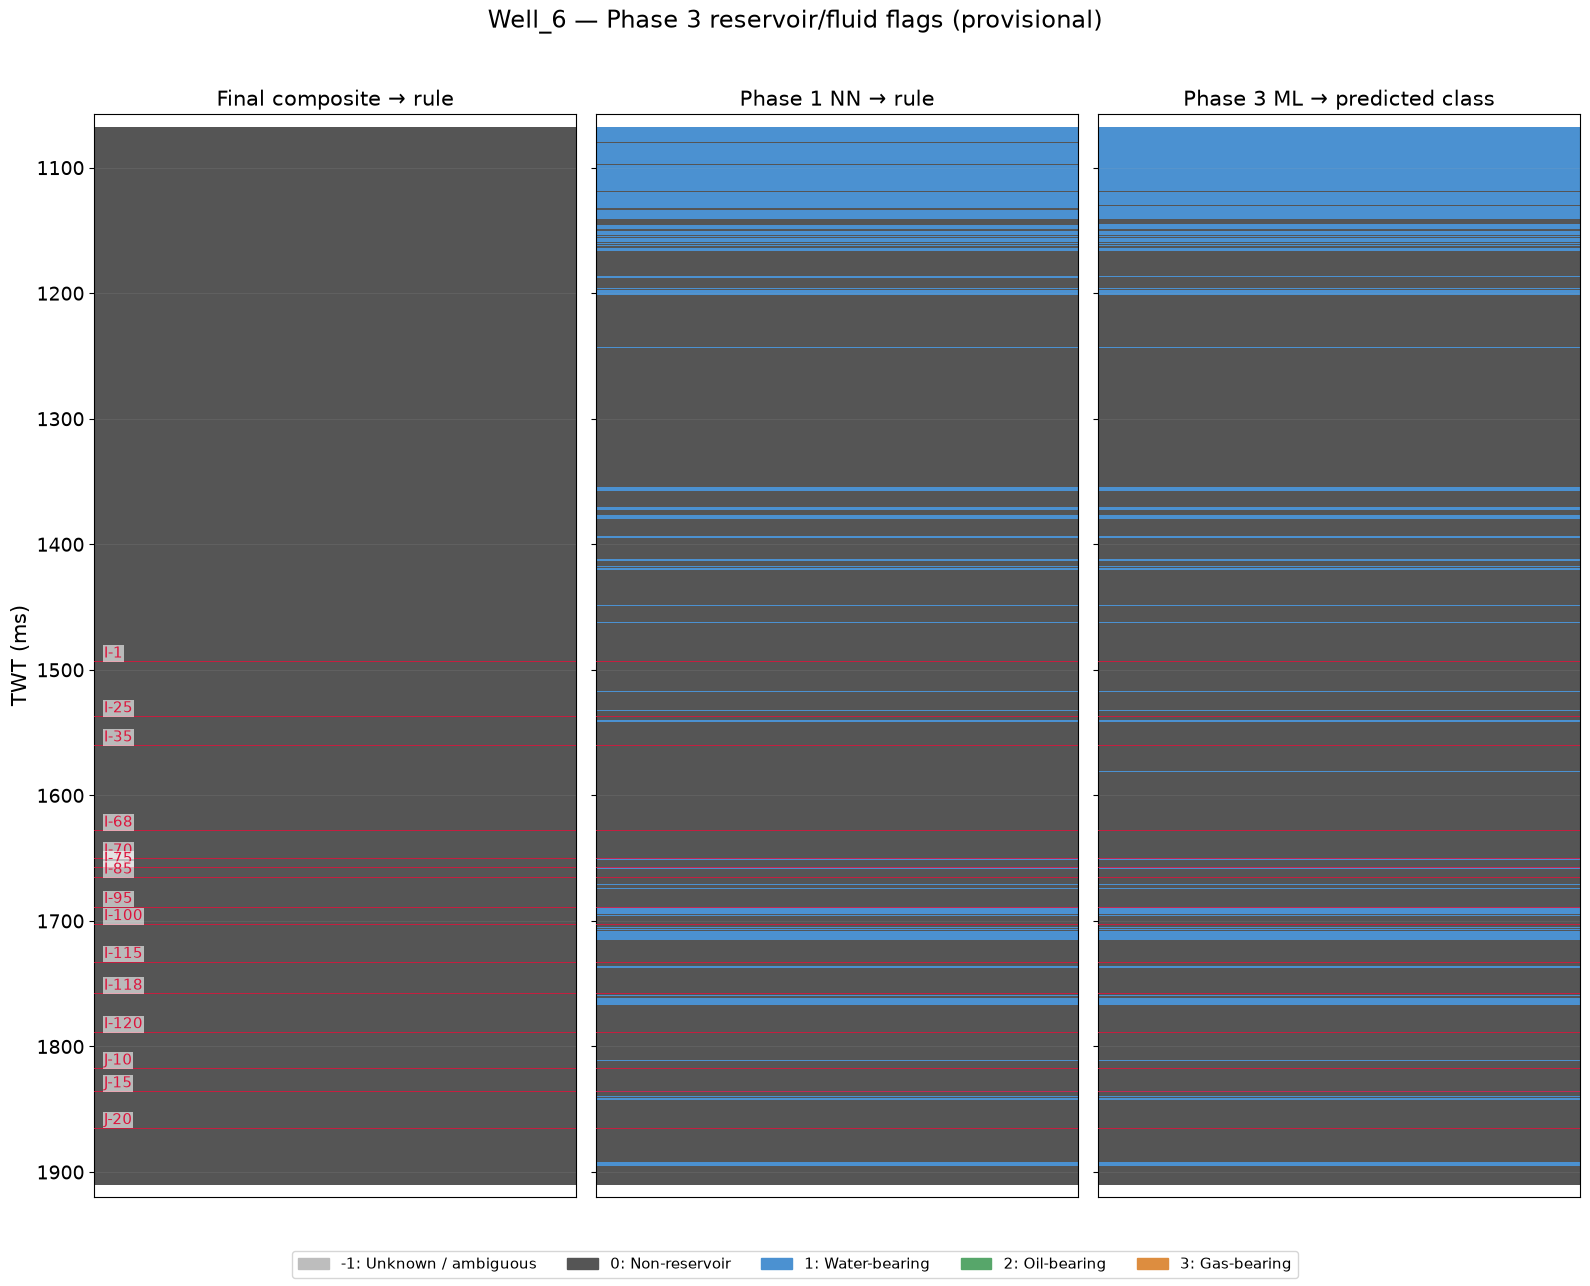

Saved full-depth QC: /home/apgce_team_08/link-to-apgce_team_08/Well_4_6_7_Phase3_FluidReservoir_Output/Well_7_Phase3_3Row_TWT_QC.png


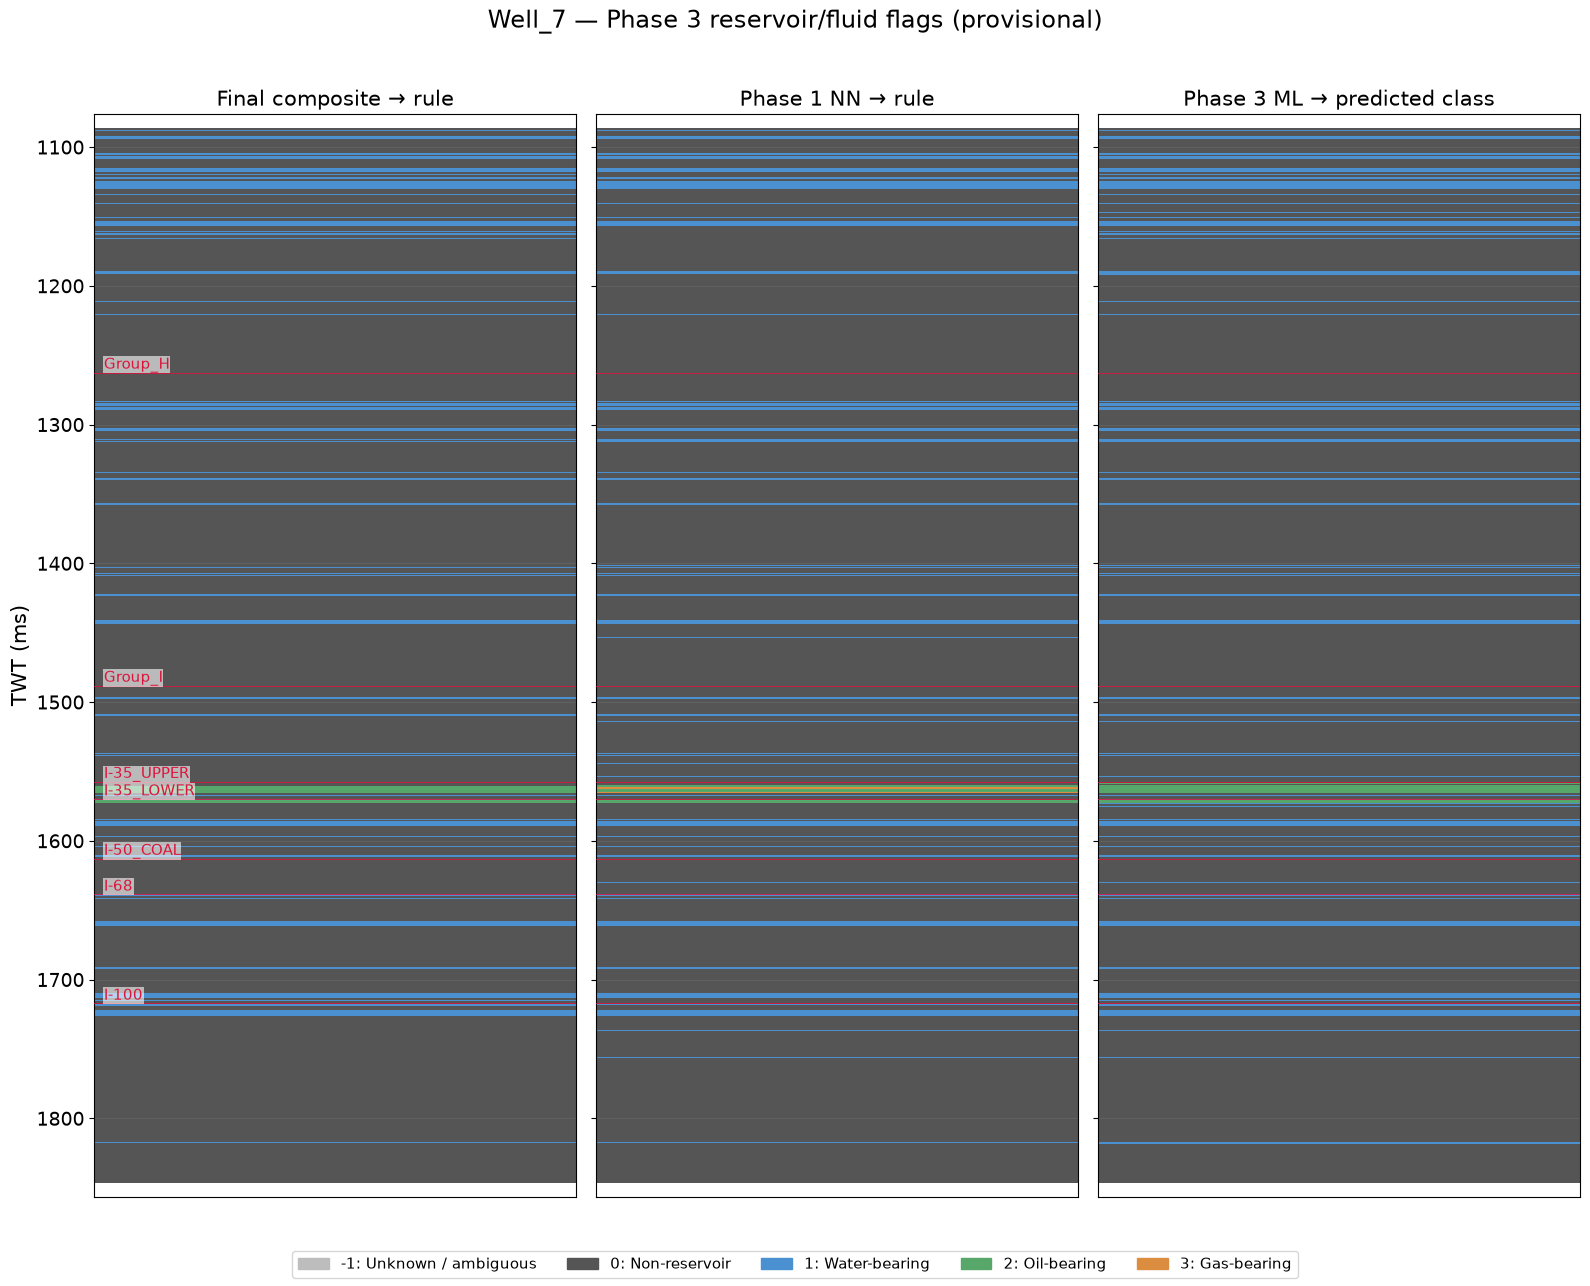

In [94]:
# Phase 3F — Full-width fluid-class tracks + interactive TWT zoom / pan
# Run Phase 3A–3E first. ipywidgets is required for interactive controls.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import ipywidgets as widgets
from IPython.display import display

PHASE3F_CODES = [-1, 0, 1, 2, 3]
PHASE3F_CMAP = ListedColormap([FLUID_COLORS[k] for k in PHASE3F_CODES])
PHASE3F_NORM = BoundaryNorm(np.arange(-1.5, 4.5, 1), PHASE3F_CMAP.N)
PHASE3F_TRACK_WIDTH = 1.0  # full width of each classification subplot
PHASE3F_FIGSIZE = (16, 13)
PHASE3F_TICK_FONT = 14
PHASE3F_TITLE_FONT = 15
PHASE3F_MARKER_FONT = 11
PHASE3F_MIN_WINDOW_MS = 20.0  # minimum zoom window


def phase3f_track(frame, flag_col):
    # Sort, remove invalid TWT, and aggregate duplicate TWT values.
    # Duplicate picks at one TWT: retain last classification deterministically.
    df = pd.DataFrame({
        'TWT_ms': pd.to_numeric(frame['TWT_ms'], errors='coerce'),
        'flag': pd.to_numeric(frame[flag_col], errors='coerce').fillna(-1)
    }).dropna(subset=['TWT_ms']).sort_values('TWT_ms')
    if df.empty:
        return np.array([]), np.array([]), np.array([])
    df = df.drop_duplicates(subset=['TWT_ms'], keep='last')
    t = df['TWT_ms'].to_numpy(dtype=np.float64, copy=True)
    f = df['flag'].to_numpy(dtype=np.int32, copy=True)
    f[~np.isin(f, PHASE3F_CODES)] = -1
    if len(t) == 1:
        edges = np.array([t[0]-0.5, t[0]+0.5])
    else:
        mids = (t[:-1] + t[1:]) / 2
        edges = np.concatenate(([t[0] - (mids[0]-t[0])], mids,
                                [t[-1] + (t[-1]-mids[-1])]))
    return t, f, edges


def phase3f_prepare(well):
    frames = [
        (PHASE3_FINAL[well], 'FLUID_FLAG', 'Final composite → rule'),
        (PHASE3_PRED[well], 'FLUID_FLAG', 'Phase 1 NN → rule'),
        (PHASE3_ML[well], 'ML_FLUID_FLAG', 'Phase 3 ML → predicted class'),
    ]
    tracks = [(phase3f_track(df, col), title) for df, col, title in frames]
    markers = WELLS[well]['markers'].copy()
    if 'TWT_ms' in markers.columns:
        markers['TWT_ms'] = pd.to_numeric(markers['TWT_ms'], errors='coerce')
        markers = markers.loc[np.isfinite(markers['TWT_ms'])].copy()
    else:
        markers = markers.iloc[0:0].copy()
    spans = [edge for (t, f, edge), title in tracks if len(edge)]
    if not markers.empty:
        spans.append(markers['TWT_ms'].to_numpy(dtype=float))
    if not spans:
        raise ValueError(f'{well}: no valid TWT samples or marker times to display')
    low = min(float(np.min(s)) for s in spans) - 10
    high = max(float(np.max(s)) for s in spans) + 10
    return tracks, markers, low, high


def phase3f_plot(well, twt_top=None, twt_bottom=None, save=False):
    tracks, markers, full_top, full_bottom = PHASE3F_PREPARED[well]
    top = full_top if twt_top is None else float(twt_top)
    bottom = full_bottom if twt_bottom is None else float(twt_bottom)
    if bottom <= top:
        raise ValueError('TWT bottom must be deeper (larger) than TWT top')
    fig, axes = plt.subplots(1, 3, figsize=PHASE3F_FIGSIZE, sharey=True)
    for ax, ((t, flags, edges), title_) in zip(axes, tracks):
        if len(flags):
            # 2-D color strip spanning the FULL horizontal width, unlike scatter(x=0).
            # Each sample occupies its corresponding TWT interval.
            ax.pcolormesh(
                np.array([0.0, PHASE3F_TRACK_WIDTH]), edges,
                flags.reshape(-1, 1), cmap=PHASE3F_CMAP,
                norm=PHASE3F_NORM, shading='flat', rasterized=True
            )
        for _, mk in markers.iterrows():
            tm = float(mk['TWT_ms'])
            if top <= tm <= bottom:
                ax.axhline(tm, color='crimson', lw=0.7, alpha=0.85, zorder=4)
                if ax is axes[0]:
                    ax.text(0.02, tm, str(mk.get('Marker', '')),
                            fontsize=PHASE3F_MARKER_FONT, va='bottom',
                            color='crimson', zorder=5,
                            bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', pad=0.5))
        ax.set_xlim(0, PHASE3F_TRACK_WIDTH)
        ax.set_ylim(bottom, top)  # shallow at top, deep at bottom
        ax.set_xticks([])
        ax.set_title(title_, fontsize=PHASE3F_TITLE_FONT)
        ax.tick_params(axis='y', labelsize=PHASE3F_TICK_FONT)
        ax.grid(axis='y', alpha=0.12)
    axes[0].set_ylabel('TWT (ms)', fontsize=15)
    legend = [Patch(color=FLUID_COLORS[k], label=f'{k}: {FLUID_NAMES[k]}')
              for k in PHASE3F_CODES]
    fig.legend(handles=legend, loc='lower center', ncol=5, fontsize=11)
    fig.suptitle(f'{well} — Phase 3 reservoir/fluid flags (provisional)', fontsize=17)
    fig.tight_layout(rect=(0, 0.055, 1, 0.96))
    if save:
        path = PHASE3_OUT / f'{well}_Phase3_3Row_TWT_QC.png'
        fig.savefig(path, dpi=150, bbox_inches='tight')
        print('Saved full-depth QC:', path)
    plt.show()
    plt.close(fig)


PHASE3F_PREPARED = {well: phase3f_prepare(well) for well in WELLS}

# Save full-depth static QC for every well (unchanged filenames for Phase 3G).
for well in WELLS:
    phase3f_plot(well, save=True)

# Interactive range slider: drag either handle to zoom, or drag the selected
# range between handles to pan up/down in TWT. Select a well from dropdown.
phase3f_well = widgets.Dropdown(options=list(WELLS), description='Well:',
                                 layout=widgets.Layout(width='310px'))
phase3f_range = widgets.FloatRangeSlider(
    description='TWT (ms):', continuous_update=False, readout=True,
    readout_format='.1f', layout=widgets.Layout(width='95%'),
    style={'description_width': '90px'})
phase3f_reset = widgets.Button(description='Reset full depth', icon='refresh')
phase3f_output = widgets.Output()



def phase3f_set_range(well):
    """
    Safely update the TWT range slider when switching wells.
    Prevents TraitError: setting min > max.
    """

    _, _, low, high = PHASE3F_PREPARED[well]

    low = float(low)
    high = float(high)

    if not np.isfinite(low) or not np.isfinite(high):
        raise ValueError(
            f"{well}: invalid TWT range ({low}, {high})"
        )

    if high <= low:
        raise ValueError(
            f"{well}: TWT maximum must exceed minimum"
        )

    # Temporarily expand slider bounds before tightening them.
    # This avoids transient invalid min/max combinations.
    with phase3f_range.hold_trait_notifications():

        phase3f_range.min = min(
            float(phase3f_range.min), low
        )

        phase3f_range.max = max(
            float(phase3f_range.max), high
        )

        phase3f_range.value = (low, high)

        # Now safely set the exact limits for this well
        phase3f_range.min = low
        phase3f_range.max = high

        phase3f_range.step = max(
            (high - low) / 1000.0,
            0.1
        )



def phase3f_redraw(change=None):
    well = phase3f_well.value
    top, bottom = phase3f_range.value
    with phase3f_output:
        phase3f_output.clear_output(wait=True)
        if bottom-top < PHASE3F_MIN_WINDOW_MS:
            print(f'Zoom window must be at least {PHASE3F_MIN_WINDOW_MS:g} ms.')
        else:
            phase3f_plot(well, top, bottom, save=False)


def phase3f_change_well(change):
    if change['name'] == 'value' and change['new'] is not None:
        phase3f_set_range(change['new'])
        phase3f_redraw()


def phase3f_reset_view(button):
    phase3f_set_range(phase3f_well.value)
    phase3f_redraw()

phase3f_well.observe(phase3f_change_well, names='value')
phase3f_range.observe(phase3f_redraw, names='value')
phase3f_reset.on_click(phase3f_reset_view)
phase3f_set_range(phase3f_well.value)
display(widgets.VBox([widgets.HBox([phase3f_well, phase3f_reset]),
                      phase3f_range, phase3f_output]))
phase3f_redraw()


In [95]:
# Phase 3G — Save three-phase learning package and QC outputs for Phase 4
# The package intentionally references the trained Phase 1 model artifacts and
# stores the trained Phase 3 classifier + complete feature and rule metadata.
for well in WELLS:
    PHASE3_PRED[well].to_csv(PHASE3_OUT/f'{well}_Phase3_NN_Rule_Flags.csv',index=False)
    PHASE3_FINAL[well].to_csv(PHASE3_OUT/f'{well}_Phase3_Final_Reference_Flags.csv',index=False)
    PHASE3_ML[well].to_csv(PHASE3_OUT/f'{well}_Phase3_ML_Predictions.csv',index=False)
PHASE3_DISTRIBUTION.to_csv(PHASE3_OUT/'Phase3_Fluid_Flag_Distribution.csv',index=False)
LOWO3_TABLE.to_csv(PHASE3_OUT/'Phase3_LOWO_Classifier_Diagnostics.csv',index=False)
LOWO3_SAMPLES.to_csv(PHASE3_OUT/'Phase3_LOWO_Sample_Predictions.csv',index=False)
joblib.dump(FINAL_PHASE3_MODEL,PHASE3_OUT/'Phase3_FluidClassifier.joblib')
# Copy locally generated Phase 1 artifacts so Phase 4 has a portable bundle.
BUNDLE=PHASE3_OUT/'Three_Phase_Learned_Bundle'
BUNDLE.mkdir(exist_ok=True)
for source in [PHASE1_MODEL_PATH,PHASE1_PREP_PATH,PHASE1_MANIFEST_PATH]:
    if not source.is_file():raise FileNotFoundError(source)
    shutil.copy2(source,BUNDLE/source.name)
shutil.copy2(PHASE3_OUT/'Phase3_FluidClassifier.joblib',BUNDLE/'Phase3_FluidClassifier.joblib')
# Record how Phase 2 lithology is derived (it has no separately trained ML weights).
package={
 'version':'1.0','source_wells':list(WELLS),
 'phase1':{'model_file':PHASE1_MODEL_PATH.name,'preprocessing_file':PHASE1_PREP_PATH.name,
           'manifest_file':PHASE1_MANIFEST_PATH.name,
           'method':'Physics-loss multi-output neural network'},
 'phase2':{'method':'Rule-based lithology from Phase 1 composite predictions',
           'coal_threshold':COAL_THRESHOLD,'dominant_min_fraction':DOMINANT_MIN_FRACTION,
           'dominance_margin':DOMINANCE_MARGIN,'require_all_components':REQUIRE_ALL_LITHO_COMPONENTS,
           'shale_curve_preference':list(SHALE_PREFERENCE),
           'min_coal_thickness_m':MIN_COAL_THICKNESS_M,'max_coal_sample_gap_m':MAX_COAL_SAMPLE_GAP_M},
 'phase3':{'classifier_file':'Phase3_FluidClassifier.joblib','features':PHASE3_MODEL_FEATURES,
           'rules':PHASE3_PARAMS,'class_names':{str(k):v for k,v in FLUID_NAMES.items()},
           'confidence_threshold':PHASE3_CONFIDENCE_THRESHOLD,
           'trained_classes':[int(x) for x in FINAL_PHASE3_MODEL.classes_],
           'unknown_class':-1},
 'well_processing':{'datum_offsets_m':DATUM_OVERRIDES_M,'depth_tolerance_m':DEPTH_TOLERANCE_M,
                    'measured_inputs':list(INPUTS),'approved_marker_mapping':APPROVED_MARKER_MAPPING,
                    'marker_vocabulary':list(MARKER_VOCABULARY),
                    'physics_parameters':PHYSICS_PARAMS},
 'validation_warning':'All three wells were used to train the final Phase 1 model; Phase 3 classifier LOWO is NOT an independent end-to-end test.',
 'deployment_note':'Phase 4 must reproduce raw LAS parsing, deviation/TVDSS/checkshot, marker encoding and physics features exactly. Verify unknown well marker names, units and datum. Never use finalized composite targets as Phase 1 inputs.'
}
(BUNDLE/'Three_Phase_Learning_Manifest.json').write_text(json.dumps(package,indent=2,default=str))
summary=pd.DataFrame([
 {'Phase':'1','Learning':'Measured logs + marker/physics features → finalized composite curves',
  'Reusable':'PhysicsLossNN.pt + preprocessing.joblib + manifest'},
 {'Phase':'2','Learning':'Rule-derived shale/siltstone/sandstone/coal from predicted composite volumes',
  'Reusable':'Interpretation thresholds, lithology logic; no independent trained classifier'},
 {'Phase':'3','Learning':'Predicted composite curves → provisional fluid/reservoir class',
  'Reusable':'Phase3_FluidClassifier.joblib + class definitions and thresholds'},
])
summary.to_csv(BUNDLE/'Three_Phase_Learning_Summary.csv',index=False)
display(summary)
print('Phase 3 output:',PHASE3_OUT)
print('Phase 4 reusable package:',BUNDLE)
print('Bundle files:',sorted(p.name for p in BUNDLE.iterdir()))

,Phase,Learning,Reusable
0,1,Measured logs + marker/physics features → fina...,PhysicsLossNN.pt + preprocessing.joblib + mani...
1,2,Rule-derived shale/siltstone/sandstone/coal fr...,"Interpretation thresholds, lithology logic; no..."
2,3,Predicted composite curves → provisional fluid...,Phase3_FluidClassifier.joblib + class definiti...


Phase 3 output: /home/apgce_team_08/link-to-apgce_team_08/Well_4_6_7_Phase3_FluidReservoir_Output
Phase 4 reusable package: /home/apgce_team_08/link-to-apgce_team_08/Well_4_6_7_Phase3_FluidReservoir_Output/Three_Phase_Learned_Bundle
Bundle files: ['Phase3_FluidClassifier.joblib', 'PhysicsLossNN_Manifest.json', 'Three_Phase_Learning_Manifest.json', 'Three_Phase_Learning_Summary.csv', 'Well4_6_7_PhysicsLossNN.pt', 'Well4_6_7_PhysicsLossNN_Preprocessing.joblib']


## Phase 4 handoff — Apply learned models to other wells

The `Three_Phase_Learned_Bundle` contains the trained Phase 1 NN, its preprocessing and feature manifest, Phase 2 rule parameters, the trained Phase 3 classifier and a complete configuration manifest. For a new well: (1) load measured LAS, deviation/checkshot and markers; (2) convert MDKB→TVD→TVDSS→TWT with **that well's own verified datum**; (3) reproduce Phase 1 marker one-hot and physics features using saved training vocabulary and parameters; (4) infer composite curves; (5) apply Phase 2 lithology rules; (6) apply Phase 3 rules and classifier; (7) export uncertainty, missing-data flags and QC. **Do not use the training-well hardcoded datum offsets for new wells.**

**Caution:** A Phase 3 classifier trained on Phase 1 predictions of the training wells may learn artifacts specific to those wells. To establish transfer accuracy, test the complete frozen pipeline on a fourth independent well with finalized composite interpretation and verified fluid evidence. Confirm fluid indicator semantics (`VGAS`, `VOIL`) and tune thresholds before operational use.
**Deployment:** Phase 4 must run the same `enforce_reservoir_thickness` logic after classifier inference; the manifest stores its parameters, but the classifier alone does not enforce minimum bed thickness.
